# Simple EDA — latest session

This notebook is a deliberately primitive pass over the latest recorded session.
It reads `session.json`, `protocol.json`, `events.jsonl`, `attempt.json`,
`csi.csv`, and `radio_timing.csv` directly with `json`, `pathlib`, `pandas`, and
`matplotlib`. Sections 0–4 keep these calculations self-contained. Section 5 reuses the
shared phase-motion loader and tested burst measurements from `fall_detection`.

The notebook has four parts:

- **Part 1 — general overview (sections 0–3).** Label distribution, packet
  counts, and effective packet rate.
- **Part 2 — raw CSI (section 4).** One fall and one non-fall attempt, showing
  amplitude, raw wrapped phase, and calibrated phase for every subcarrier slot
  with countdown, action, and recovery bands.
- **Part 3 — temporal patterns (section 5).** 100 ms circular phase-motion
  traces and burst measurements across usable attempts, with separate receivers
  and raw/calibrated representations.
- **Part 4 — separate subcarriers (section 6).** Signed phase-change matrices
  for repeated direction-controlled attempts. Each heatmap retains every
  physical subcarrier and packet separately.

The latest session is selected by the newest session-id timestamp under
`data/raw/sessions/`. Earlier sessions are not read.

The general overview answers three questions:

1. How are the activity labels distributed?
2. How many sensing-link packets belong to each label, counting both receivers?
3. What effective packet rate does each label achieve, counting both receivers?

**Scope.** The latest session only. An *attempt* is one recording of a protocol
scenario; a retry is another attempt of the same trial. A *receiver recording* is
one attempt seen by one receiver (`rx-1` or `rx-2`). One CSI row is one packet for
one receiver.

**Usable attempt.** An attempt with `status == "accepted"`, not marked
`inclusion == "exclude"`, and not marked `quality == "bad"` in the optional
review sidecar. Packet counts and rates use usable attempts; the label table
keeps skipped trials and failed attempts visible.

**Sensing link.** Only rows whose source MAC is the session transmitter and whose
`sig_mode` is `4` (HE20) are counted as sensing packets. Raw CSI rows are also
reported because ambient Wi-Fi frames are recorded in the same files.

**“All rx” means both receiver streams.** The same transmitted frame is stored
once for every receiver that heard it. Summing both receivers therefore counts
a frame once per receiver that heard it, so the all-rx total is not a count of
unique frames. A per-receiver rate is near 100 Hz; the two-receiver sum is near
200 packets/s. Neither number is de-duplicated across receivers.

**Part 2 scope.** Section 4 compares one `walk_to_fall` and one `walk_to_sit`
attempt. It is an illustrative pair, not a classification result. The raw-phase
view applies no calibration; a separate calibrated view removes the per-packet
linear trend. No subcarrier aggregation or temporal filtering is applied.


In [1]:
%matplotlib inline

from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").exists()
)
SESSIONS_DIR = ROOT / "data/raw/sessions"
SESSION_DIRS = sorted(
    path.parent for path in SESSIONS_DIR.glob("*/session.json")
)
if not SESSION_DIRS:
    raise FileNotFoundError(f"No session manifests under {SESSIONS_DIR}")
SESSION_DIR = SESSION_DIRS[-1]
SENSING_SIG_MODE = 4

FALL_LABELS = ["walk_to_fall", "sit_to_fall", "stand_to_fall"]
NON_FALL_LABELS = ["walk_to_sit", "sit_to_walk", "sit_to_stand"]
LABEL_ORDER = FALL_LABELS + NON_FALL_LABELS

LABEL_DISPLAY = {label: label.replace("_to_", "→") for label in LABEL_ORDER}
LABEL_COLORS = {
    "walk_to_fall": "#c2410c",
    "sit_to_fall": "#ea580c",
    "stand_to_fall": "#f59e0b",
    "walk_to_sit": "#1d4ed8",
    "sit_to_walk": "#3b82f6",
    "sit_to_stand": "#93c5fd",
}
RX_COLORS = {"rx-1": "#4c1d95", "rx-2": "#a78bfa"}
CLASS_COLORS = {"fall": "#ea580c", "non-fall": "#3b82f6"}

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.axisbelow": True,
    }
)

print(f"Repository root: {ROOT}")
print(f"Sessions found: {len(SESSION_DIRS)}")
print(f"Reading only: {SESSION_DIR.name}")
print(f"Earlier sessions not read: {len(SESSION_DIRS) - 1}")


Repository root: /home/khaelano/Projects/radio-fall-detection
Sessions found: 3
Reading only: 20261026T174653764289Z
Earlier sessions not read: 2


## 0. Read the latest session

The session directory is chosen by the timestamp in its name. `session.json`
supplies the session identity, protocol, transmitter MAC, and nominal rate.
`protocol.json` supplies the planned trial grid; `events.jsonl` records which
trials were accepted or skipped. `attempt.json` supplies the scenario, status,
and planned label.

The label resolution order follows the dataset documentation:
`reference_truth_label` → review-sidecar correction → planned `activity_label`.
Review metadata, when present, overrides the session participant.


In [2]:
def read_json(path: Path) -> dict:
    # Read one UTF-8 JSON file.
    return json.loads(path.read_text())


manifest = read_json(SESSION_DIR / "session.json")
review_path = SESSION_DIR / "session_review.json"
review = read_json(review_path) if review_path.exists() else {}
review_metadata = review.get("metadata", {})

manifest_participant = manifest.get("participant_id") or ""
effective_participant = (
    review_metadata.get("participant_id") or manifest_participant or "unknown"
)
environment = manifest.get("environment", {})
inventory = environment.get("radio_inventory", {})
transmitter_mac = inventory.get("transmitter", {}).get("mac", "").lower()
session_id = manifest.get("session_id", SESSION_DIR.name)

sessions = pd.DataFrame(
    [
        {
            "session_id": session_id,
            "session_status": manifest.get("status", ""),
            "protocol_id": manifest.get("protocol_id", ""),
            "started_at_utc": manifest.get("started_at_utc", ""),
            "manifest_participant": manifest_participant,
            "participant_id": effective_participant,
            "tx_mac": transmitter_mac,
            "nominal_rate_hz": environment.get("nominal_rate_hz"),
        }
    ]
)

protocol = read_json(SESSION_DIR / "protocol.json")
planned_rows = []
ordinal = 0
for block in protocol.get("blocks", []):
    for scenario in block.get("scenarios", []):
        repetitions = int(scenario.get("repetitions", 1))
        for repetition in range(1, repetitions + 1):
            ordinal += 1
            planned_rows.append(
                {
                    "trial_ordinal": ordinal,
                    "scenario_id": scenario["id"],
                    "label": scenario.get("activity_label", ""),
                    "repetition": repetition,
                }
            )
planned_trials = pd.DataFrame(planned_rows)

attempt_records = []
for attempt_path in sorted(SESSION_DIR.glob("trials/*/attempt_*/attempt.json")):
    attempt = read_json(attempt_path)
    attempt_dir = attempt_path.parent
    review_key = attempt_dir.relative_to(SESSION_DIR).as_posix()
    review_attempt = review.get("attempts", {}).get(review_key, {})
    planned_label = attempt.get("activity_label", "")
    label = (
        attempt.get("reference_truth_label")
        or review_attempt.get("activity_label")
        or planned_label
    )

    started = attempt.get("started_monotonic_ns")
    ended = attempt.get("ended_monotonic_ns")
    attempt_records.append(
        {
            "session_id": session_id,
            "attempt_key": (
                f"{session_id}/"
                f"{attempt['trial_ordinal']:03d}/"
                f"{attempt_dir.name.removeprefix('attempt_')}"
            ),
            "attempt_relpath": review_key,
            "trial_ordinal": attempt["trial_ordinal"],
            "scenario_id": attempt.get("scenario_id", ""),
            "planned_label": planned_label,
            "label": label,
            "status": attempt.get("status", ""),
            "action_confirmed": attempt.get("action_confirmed"),
            "review_inclusion": review_attempt.get("inclusion", "unreviewed"),
            "review_quality": review_attempt.get("quality", "unreviewed"),
            "attempt_duration_s": (
                (ended - started) / 1e9
                if started is not None and ended is not None
                else np.nan
            ),
        }
    )
attempts = pd.DataFrame(attempt_records)

events = pd.DataFrame(
    [
        json.loads(line)
        for line in (SESSION_DIR / "events.jsonl").read_text().splitlines()
        if line.strip()
    ]
)
resolved = events.loc[
    events["kind"].eq("trial_resolved"), ["trial_ordinal", "disposition", "attempt"]
].copy()
resolved = resolved.merge(
    planned_trials[["trial_ordinal", "scenario_id", "label"]],
    on="trial_ordinal",
    how="left",
    validate="many_to_one",
)
skipped_trials = resolved.loc[resolved["disposition"].eq("skipped")].copy()

unexpected_labels = sorted(set(attempts["label"]) - set(LABEL_ORDER))
if unexpected_labels:
    raise ValueError(
        f"Add new labels to LABEL_ORDER and LABEL_COLORS: {unexpected_labels}"
    )

attempts["label"] = pd.Categorical(
    attempts["label"], categories=LABEL_ORDER, ordered=True
)
attempts["binary_class"] = np.where(
    attempts["label"].isin(FALL_LABELS), "fall", "non-fall"
)
attempts["in_scope"] = (
    attempts["status"].eq("accepted")
    & attempts["review_inclusion"].ne("exclude")
    & attempts["review_quality"].ne("bad")
)
attempts["planned_scenario_id"] = attempts["trial_ordinal"].map(
    planned_trials.set_index("trial_ordinal")["scenario_id"]
)
scenario_mismatches = int(
    (attempts["scenario_id"] != attempts["planned_scenario_id"]).sum()
)

scope = attempts.loc[attempts["in_scope"]].copy()

print(f"Session: {session_id} ({manifest.get('status')})")
print(f"Planned trials: {len(planned_trials)}")
print(f"Recorded attempts: {len(attempts)}")
print(f"Usable attempts: {len(scope)}")
print(
    "Trial resolutions: "
    f"{len(resolved)} total, "
    f"{int(resolved['disposition'].eq('accepted').sum())} accepted, "
    f"{len(skipped_trials)} skipped"
)
print(
    "Attempt-level review decisions: "
    f"{int((attempts['review_inclusion'] != 'unreviewed').sum())}"
)
print(
    "Label corrections from reference truth or review: "
    f"{int((attempts['label'].astype(str) != attempts['planned_label']).sum())}"
)
print(f"Attempt/scenario ordinal mismatches: {scenario_mismatches}")


Session: 20261026T174653764289Z (complete)
Planned trials: 160
Recorded attempts: 171
Usable attempts: 154
Trial resolutions: 160 total, 154 accepted, 6 skipped
Attempt-level review decisions: 0
Label corrections from reference truth or review: 0
Attempt/scenario ordinal mismatches: 0


### Session at a glance

The table keeps the manifest participant beside the effective participant because
the review sidecar may override it.


In [3]:
session_table = sessions.copy()
session_table["recorded_attempts"] = len(attempts)
session_table["usable_attempts"] = int(scope["in_scope"].sum())
session_table["planned_trials"] = len(planned_trials)
session_table["skipped_trials"] = len(skipped_trials)
session_table["started_at_utc"] = pd.to_datetime(
    session_table["started_at_utc"], utc=True
).dt.strftime("%Y-%m-%d %H:%M UTC")
display(
    session_table[
        [
            "session_id",
            "participant_id",
            "manifest_participant",
            "session_status",
            "protocol_id",
            "started_at_utc",
            "planned_trials",
            "skipped_trials",
            "recorded_attempts",
            "usable_attempts",
        ]
    ]
)

participant_overrides = session_table.loc[
    session_table["participant_id"].ne(session_table["manifest_participant"])
]
if not participant_overrides.empty:
    print("Participant overridden by review metadata:")
    display(
        participant_overrides[
            ["session_id", "manifest_participant", "participant_id"]
        ]
    )


,session_id,participant_id,manifest_participant,session_status,protocol_id,started_at_utc,planned_trials,skipped_trials,recorded_attempts,usable_attempts
0,20261026T174653764289Z,akmal,lano,complete,fall-collection-simple-v1,2026-10-26 17:46 UTC,160,6,171,154


Participant overridden by review metadata:


,session_id,manifest_participant,participant_id
0,20261026T174653764289Z,lano,akmal


## 1. Distribution of labels

Count trials and attempts separately. The protocol plans 160 trials. A trial can
end as accepted (an attempt exists and is usable) or skipped (no attempt). A trial
can also have failed attempts before it is accepted on a retry.

The simplified protocol explains most of the label counts:

- `walk_to_fall`, `stand_to_fall`, `walk_to_sit`, and `sit_to_walk` each have
  16 scenarios × 2 repetitions = 32 planned trials.
- `sit_to_fall` has 12 scenarios × 2 = 24 planned trials; a seated person never
  falls backward in this protocol, so it has fewer scenarios than the other fall
  activities.
- `sit_to_stand` has 4 scenarios × 2 = 8 planned trials because it has no end
  direction.

The session resolved all 160 planned trials: 154 were accepted and 6 were
skipped. The six skipped trials are three `sit_to_fall` scenarios, both
repetitions each. The 171 `attempt.json` files include 17 failed attempts that
were retried.


In [4]:
invalid_attempts = (
    attempts.loc[attempts["status"].eq("invalid")]
    .groupby("label", observed=True)
    .size()
)
rejected_attempts = (
    attempts.loc[attempts["status"].eq("rejected")]
    .groupby("label", observed=True)
    .size()
)

label_coverage = pd.DataFrame(
    {
        "planned_trials": planned_trials.groupby("label").size(),
        "skipped_trials": skipped_trials.groupby("label").size(),
        "recorded_attempts": attempts.groupby("label", observed=True).size(),
        "usable_attempts": scope.groupby("label", observed=True).size(),
        "invalid_attempts": invalid_attempts,
        "rejected_attempts": rejected_attempts,
    }
).reindex(LABEL_ORDER).fillna(0).astype(int)
label_coverage["usable_share_pct"] = (
    100 * label_coverage["usable_attempts"] / label_coverage["usable_attempts"].sum()
)
label_coverage = label_coverage[
    [
        "planned_trials",
        "skipped_trials",
        "recorded_attempts",
        "usable_attempts",
        "invalid_attempts",
        "rejected_attempts",
        "usable_share_pct",
    ]
]
label_coverage.index = label_coverage.index.astype(str)
total = label_coverage.sum(numeric_only=True)
total["usable_share_pct"] = 100.0
label_coverage.loc["total"] = total
count_columns = [
    "planned_trials",
    "skipped_trials",
    "recorded_attempts",
    "usable_attempts",
    "invalid_attempts",
    "rejected_attempts",
]
label_coverage[count_columns] = label_coverage[count_columns].astype(int)
display(label_coverage)


,planned_trials,skipped_trials,recorded_attempts,usable_attempts,invalid_attempts,rejected_attempts,usable_share_pct
label,,,,,,,
walk_to_fall,32,0,34,32,2,0,20.779
sit_to_fall,24,6,22,18,4,0,11.688
stand_to_fall,32,0,39,32,7,0,20.779
walk_to_sit,32,0,32,32,0,0,20.779
sit_to_walk,32,0,35,32,2,1,20.779
sit_to_stand,8,0,9,8,0,1,5.195
total,160,6,171,154,15,2,100.000


In [5]:
class_summary = pd.DataFrame(
    {
        "recorded": attempts.groupby("binary_class", observed=True).size(),
        "usable": scope.groupby("binary_class", observed=True).size(),
    }
).reindex(["fall", "non-fall"])
class_summary["usable_share_pct"] = (
    100 * class_summary["usable"] / class_summary["usable"].sum()
)
display(class_summary)


,recorded,usable,usable_share_pct
binary_class,,,
fall,95,82,53.247
non-fall,76,72,46.753


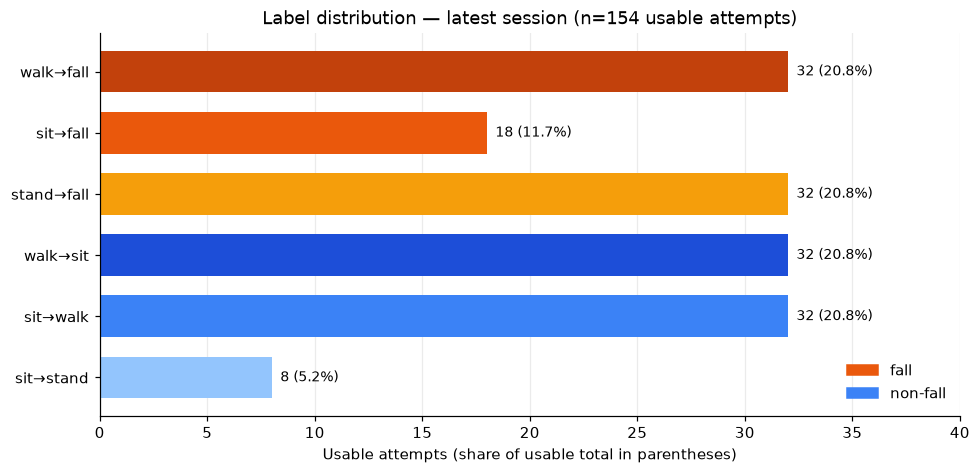

In [6]:
label_counts = (
    scope.groupby("label", observed=True).size().reindex(LABEL_ORDER, fill_value=0)
)

fig, ax = plt.subplots(figsize=(8.8, 4.2), layout="constrained")
positions = np.arange(len(LABEL_ORDER))
bars = ax.barh(
    positions,
    label_counts.to_numpy(),
    color=[LABEL_COLORS[label] for label in LABEL_ORDER],
    height=0.68,
)
ax.set_yticks(positions, [LABEL_DISPLAY[label] for label in LABEL_ORDER])
ax.invert_yaxis()
for bar, count in zip(bars, label_counts):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({100 * count / label_counts.sum():.1f}%)",
        va="center",
        fontsize=9,
    )
ax.set_xlabel("Usable attempts (share of usable total in parentheses)")
ax.set_xlim(0, label_counts.max() * 1.25)
ax.set_title(
    f"Label distribution — latest session (n={label_counts.sum()} usable attempts)"
)
ax.grid(axis="y", visible=False)
ax.legend(
    [
        plt.Rectangle((0, 0), 1, 1, color=CLASS_COLORS["fall"]),
        plt.Rectangle((0, 0), 1, 1, color=CLASS_COLORS["non-fall"]),
    ],
    ["fall", "non-fall"],
    loc="lower right",
    frameon=False,
)
plt.show()


Fall attempts outnumber non-fall attempts 82 to 72 (53.2% vs 46.8%). The label
counts follow the protocol grid except for `sit_to_fall`: it has 24 planned trials
but only 18 usable because three scenarios (six trials) were skipped.
`sit_to_stand` has 8 usable trials by design (four scenarios, no end direction).
The 17 failed attempts (15 invalid, 2 rejected) are retries; they do not reduce
the accepted trial count.


## 2. Packet counts per label (both receivers)

A packet count here is the number of sensing-link CSI rows. It is not a count of
unique transmissions: each transmitted frame appears once per receiver that
heard it, so the all-rx count is roughly twice the number of unique frames.

The scan reads `id`, `mac`, and `sig_mode` from `csi.csv`, and `sequence` and
`rx_callback_timestamp_us` from `radio_timing.csv`. Raw CSI rows are counted too;
they include ambient Wi-Fi frames, so `sensing_share_pct` shows how much of each
label's raw data is the intended link. Counts below use usable attempts; the
label table in section 1 keeps skipped trials and failed attempts visible. Rates
are computed in the same pass and summarised in section 3.


In [7]:
def scan_receiver(receiver_dir: Path, transmitter_mac: str) -> dict:
    # Count sensing-link packets in one receiver recording.
    csi_path = receiver_dir / "csi.csv"
    timing_path = receiver_dir / "radio_timing.csv"
    if not csi_path.exists() or not timing_path.exists():
        return {
            "raw_csi_rows": 0,
            "sensing_packets": 0,
            "timed_packets": 0,
            "timing_rows": 0,
            "elapsed_s": np.nan,
            "rate_hz": np.nan,
            "read_error": "missing csi.csv or radio_timing.csv",
        }

    csi = pd.read_csv(csi_path, usecols=["id", "mac", "sig_mode"])
    timing = pd.read_csv(
        timing_path,
        usecols=["sequence", "rx_callback_timestamp_us"],
    )

    if csi.empty or timing.empty:
        return {
            "raw_csi_rows": len(csi),
            "sensing_packets": 0,
            "timed_packets": 0,
            "timing_rows": len(timing),
            "elapsed_s": np.nan,
            "rate_hz": np.nan,
            "read_error": "",
        }

    sensing_mask = (
        csi["mac"].str.lower().eq(transmitter_mac)
        & csi["sig_mode"].eq(SENSING_SIG_MODE)
    )
    sensing_ids = set(csi.loc[sensing_mask, "id"].astype("int64"))
    timestamps = (
        timing.loc[
            timing["sequence"].isin(sensing_ids), "rx_callback_timestamp_us"
        ]
        .dropna()
        .sort_values()
        .to_numpy(dtype="float64")
    )
    elapsed_s = (
        (timestamps[-1] - timestamps[0]) / 1e6 if len(timestamps) > 1 else np.nan
    )
    rate_hz = (
        (len(timestamps) - 1) / elapsed_s
        if pd.notna(elapsed_s) and elapsed_s > 0
        else np.nan
    )
    return {
        "raw_csi_rows": len(csi),
        "sensing_packets": len(sensing_ids),
        "timed_packets": len(timestamps),
        "timing_rows": len(timing),
        "elapsed_s": elapsed_s,
        "rate_hz": rate_hz,
        "read_error": "",
    }


receiver_records = []
read_errors = []
for attempt in attempts.itertuples(index=False):
    attempt_dir = SESSION_DIR / attempt.attempt_relpath
    receiver_root = attempt_dir / "receivers"
    if not receiver_root.exists():
        read_errors.append((attempt.attempt_key, "missing receivers directory"))
        continue
    for receiver_dir in sorted(
        path for path in receiver_root.iterdir() if path.is_dir()
    ):
        metrics = scan_receiver(receiver_dir, transmitter_mac)
        if metrics["read_error"]:
            read_errors.append((attempt.attempt_key, metrics["read_error"]))
        receiver_records.append(
            {
                "attempt_key": attempt.attempt_key,
                "receiver_id": receiver_dir.name,
                **metrics,
            }
        )

receivers = pd.DataFrame(receiver_records)
receivers = receivers.merge(
    attempts[
        [
            "attempt_key",
            "session_id",
            "label",
            "binary_class",
            "status",
            "in_scope",
            "scenario_id",
        ]
    ],
    on="attempt_key",
    how="left",
    validate="many_to_one",
)

print(
    f"Scanned {len(receivers)} receiver recordings "
    f"from {receivers['attempt_key'].nunique()} attempts."
)
print(f"Read errors: {len(read_errors)}")
if read_errors:
    display(pd.DataFrame(read_errors, columns=["attempt_key", "error"]))


Scanned 342 receiver recordings from 171 attempts.
Read errors: 0


In [8]:
attempt_packets = receivers.groupby("attempt_key", as_index=False).agg(
    receiver_recordings=("receiver_id", "nunique"),
    rate_count=("rate_hz", "count"),
    raw_csi_rows_all_rx=("raw_csi_rows", "sum"),
    sensing_packets_all_rx=("sensing_packets", "sum"),
    timed_packets_all_rx=("timed_packets", "sum"),
    timing_rows_all_rx=("timing_rows", "sum"),
    mean_elapsed_s=("elapsed_s", "mean"),
    all_rx_rate_hz=("rate_hz", lambda values: values.sum(min_count=1)),
    mean_rx_rate_hz=("rate_hz", "mean"),
    min_rx_rate_hz=("rate_hz", "min"),
    max_rx_rate_hz=("rate_hz", "max"),
)
attempt_packets = attempt_packets.merge(
    attempts[
        [
            "attempt_key",
            "session_id",
            "label",
            "binary_class",
            "status",
            "in_scope",
            "scenario_id",
            "trial_ordinal",
        ]
    ],
    on="attempt_key",
    how="left",
    validate="one_to_one",
)
attempt_packets.loc[
    attempt_packets["receiver_recordings"].ne(2)
    | attempt_packets["rate_count"].ne(2),
    "all_rx_rate_hz",
] = np.nan
packet_scope = attempt_packets.loc[attempt_packets["in_scope"]].copy()

print(f"Receiver recordings: {len(receivers):,}")
print(f"Raw CSI rows: {receivers['raw_csi_rows'].sum():,}")
print(f"Sensing-link packets: {receivers['sensing_packets'].sum():,}")
print(f"Sensing rows with a rate timestamp: {receivers['timed_packets'].sum():,}")
print(
    "Rows where timing and CSI row counts differ: "
    f"{int((receivers['timing_rows'] != receivers['raw_csi_rows']).sum())}"
)
print(
    "Sensing packets without a rate timestamp: "
    f"{int((receivers['sensing_packets'] - receivers['timed_packets']).sum())}"
)

usable_receivers = receivers.loc[receivers["in_scope"]]
scope_summary = pd.DataFrame(
    [
        [
            "recorded",
            f"{len(attempts):,}",
            f"{len(receivers):,}",
            f"{int(receivers['raw_csi_rows'].sum()):,}",
            f"{int(receivers['sensing_packets'].sum()):,}",
        ],
        [
            "usable",
            f"{len(scope):,}",
            f"{len(usable_receivers):,}",
            f"{int(usable_receivers['raw_csi_rows'].sum()):,}",
            f"{int(usable_receivers['sensing_packets'].sum()):,}",
        ],
    ],
    columns=[
        "scope",
        "attempts",
        "receiver recordings",
        "raw CSI rows (all rx)",
        "sensing packets (all rx)",
    ],
)
display(scope_summary)


Receiver recordings: 342
Raw CSI rows: 470,188
Sensing-link packets: 459,326
Sensing rows with a rate timestamp: 459,326
Rows where timing and CSI row counts differ: 0
Sensing packets without a rate timestamp: 0


,scope,attempts,receiver recordings,raw CSI rows (all rx),sensing packets (all rx)
0,recorded,171,342,"470,188","459,326"
1,usable,154,308,"450,324","439,895"


In [9]:
receiver_scope = receivers.loc[receivers["in_scope"]].copy()

label_packets = receiver_scope.groupby("label", observed=True).agg(
    attempts=("attempt_key", "nunique"),
    receiver_recordings=("receiver_id", "size"),
    raw_csi_rows_all_rx=("raw_csi_rows", "sum"),
    sensing_packets_all_rx=("sensing_packets", "sum"),
)
attempt_packet_stats = packet_scope.groupby("label", observed=True)[
    "sensing_packets_all_rx"
].agg(
    mean_packets_per_attempt="mean",
    median_packets_per_attempt="median",
    min_packets_per_attempt="min",
    max_packets_per_attempt="max",
)
label_packets = label_packets.join(attempt_packet_stats)
label_packets["sensing_share_pct"] = (
    100
    * label_packets["sensing_packets_all_rx"]
    / label_packets["raw_csi_rows_all_rx"]
)
label_packets["packet_share_pct"] = (
    100
    * label_packets["sensing_packets_all_rx"]
    / label_packets["sensing_packets_all_rx"].sum()
)
label_packets = label_packets[
    [
        "attempts",
        "receiver_recordings",
        "sensing_packets_all_rx",
        "packet_share_pct",
        "mean_packets_per_attempt",
        "median_packets_per_attempt",
        "raw_csi_rows_all_rx",
        "sensing_share_pct",
    ]
]

label_display = label_packets.copy()
label_display["sensing_packets_all_rx"] = label_display[
    "sensing_packets_all_rx"
].map("{:,}".format)
label_display["raw_csi_rows_all_rx"] = label_display[
    "raw_csi_rows_all_rx"
].map("{:,}".format)
for column in ["mean_packets_per_attempt", "median_packets_per_attempt"]:
    label_display[column] = label_display[column].map("{:,.1f}".format)
for column in ["packet_share_pct", "sensing_share_pct"]:
    label_display[column] = label_display[column].map("{:.2f}".format)
display(label_display)
print(f"Total usable sensing packets: {label_packets['sensing_packets_all_rx'].sum():,}")
print(f"Total usable raw CSI rows: {label_packets['raw_csi_rows_all_rx'].sum():,}")


,attempts,receiver_recordings,sensing_packets_all_rx,packet_share_pct,mean_packets_per_attempt,median_packets_per_attempt,raw_csi_rows_all_rx,sensing_share_pct
label,,,,,,,,
walk_to_fall,32,64,"91,947",20.90,"2,873.3","2,858.0","93,956",97.86
sit_to_fall,18,36,"50,764",11.54,"2,820.2","2,828.0","51,867",97.87
stand_to_fall,32,64,"84,715",19.26,"2,647.3","2,641.5","86,590",97.83
walk_to_sit,32,64,"101,211",23.01,"3,162.8","3,149.0","103,611",97.68
sit_to_walk,32,64,"90,125",20.49,"2,816.4","2,826.0","92,552",97.38
sit_to_stand,8,16,"21,133",4.80,"2,641.6","2,644.5","21,748",97.17


Total usable sensing packets: 439,895
Total usable raw CSI rows: 450,324


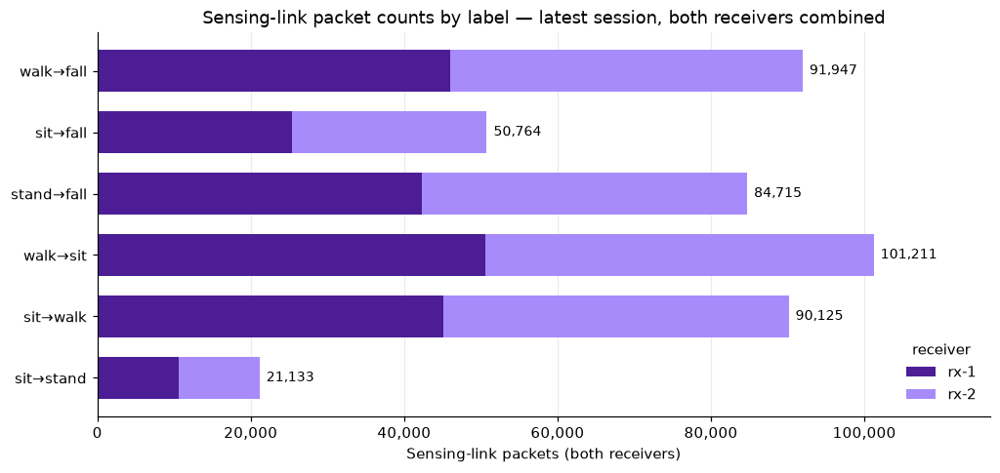

In [10]:
label_rx_packets = (
    receiver_scope.groupby(["label", "receiver_id"], observed=True)["sensing_packets"]
    .sum()
    .unstack("receiver_id")
    .reindex(LABEL_ORDER)
)
for receiver_id in RX_COLORS:
    if receiver_id not in label_rx_packets:
        label_rx_packets[receiver_id] = 0
label_rx_packets = label_rx_packets[list(RX_COLORS)].fillna(0)

fig, ax = plt.subplots(figsize=(9.2, 4.3), layout="constrained")
positions = np.arange(len(LABEL_ORDER))
left = np.zeros(len(LABEL_ORDER))
for receiver_id in RX_COLORS:
    values = label_rx_packets[receiver_id].to_numpy()
    ax.barh(
        positions,
        values,
        left=left,
        color=RX_COLORS[receiver_id],
        label=receiver_id,
        height=0.68,
    )
    left += values

ax.set_yticks(positions, [LABEL_DISPLAY[label] for label in LABEL_ORDER])
ax.invert_yaxis()
for position, total in zip(positions, left):
    ax.text(total + 900, position, f"{int(total):,}", va="center", fontsize=9)
ax.set_xlabel("Sensing-link packets (both receivers)")
ax.set_xlim(0, left.max() * 1.15)
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.set_title(
    "Sensing-link packet counts by label — latest session, both receivers combined"
)
ax.grid(axis="y", visible=False)
ax.legend(title="receiver", loc="lower right", frameon=False)
plt.show()


In [11]:
class_packets = packet_scope.groupby("binary_class", observed=True).agg(
    attempts=("attempt_key", "nunique"),
    sensing_packets_all_rx=("sensing_packets_all_rx", "sum"),
)
class_packets["packet_share_pct"] = (
    100
    * class_packets["sensing_packets_all_rx"]
    / class_packets["sensing_packets_all_rx"].sum()
)
class_display = class_packets.copy()
class_display["sensing_packets_all_rx"] = class_display[
    "sensing_packets_all_rx"
].map("{:,}".format)
class_display["packet_share_pct"] = class_display["packet_share_pct"].map(
    "{:.2f}".format
)
display(class_display)


,attempts,sensing_packets_all_rx,packet_share_pct
binary_class,,,
fall,82,"227,426",51.70
non-fall,72,"212,469",48.30


In this session, 97.7% of usable raw rows are the sensing link. Ambient frames
still account for about 10,400 rows (2.3%), and the sensing share is similar
across labels (97.2–97.9%), so ambient traffic does not explain the label-count
differences. Counting raw CSV rows would overstate every label by about the same
small amount.

Class balance at packet level is close to the attempt-level balance because most
usable attempts last roughly the same length (about 14 seconds).


In [12]:
scenario_summary = (
    packet_scope.groupby(["label", "scenario_id"], observed=True)
    .agg(
        attempts=("attempt_key", "nunique"),
        sensing_packets_all_rx=("sensing_packets_all_rx", "sum"),
        mean_packets_per_attempt=("sensing_packets_all_rx", "mean"),
        mean_rate_all_rx_hz=("all_rx_rate_hz", "mean"),
    )
    .reset_index()
    .sort_values(["label", "scenario_id"])
)
scenario_display = scenario_summary.copy()
scenario_display["sensing_packets_all_rx"] = scenario_display[
    "sensing_packets_all_rx"
].map("{:,}".format)
scenario_display["mean_packets_per_attempt"] = scenario_display[
    "mean_packets_per_attempt"
].map("{:,.1f}".format)
scenario_display["mean_rate_all_rx_hz"] = scenario_display[
    "mean_rate_all_rx_hz"
].map("{:.4f}".format)
display(scenario_display)

planned_scenario_table = planned_trials.groupby(
    ["label", "scenario_id"], as_index=False
).agg(planned_trials=("trial_ordinal", "size"))
skipped_by_scenario = skipped_trials.groupby(
    ["label", "scenario_id"], as_index=False
).agg(skipped_trials=("trial_ordinal", "size"))
accepted_scenario_ids = set(packet_scope["scenario_id"])
missing_scenarios = (
    planned_scenario_table.loc[
        ~planned_scenario_table["scenario_id"].isin(accepted_scenario_ids)
    ]
    .merge(skipped_by_scenario, on=["label", "scenario_id"], how="left")
)
missing_scenarios["skipped_trials"] = (
    missing_scenarios["skipped_trials"].fillna(0).astype(int)
)

print(f"Scenario ids with accepted attempts: {scenario_summary['scenario_id'].nunique()}")
print(f"Planned scenario ids: {planned_scenario_table['scenario_id'].nunique()}")
print("Accepted attempts per scenario:")
print(scenario_summary["attempts"].value_counts().sort_index().to_string())
print("Planned scenarios with no accepted attempts:")
display(missing_scenarios)


,label,scenario_id,attempts,sensing_packets_all_rx,mean_packets_per_attempt,mean_rate_all_rx_hz
0,walk_to_fall,walk-to-fall__start_back__end_back,2,"5,632","2,816.0",199.9989
1,walk_to_fall,walk-to-fall__start_back__end_front,2,"5,756","2,878.0",199.9988
2,walk_to_fall,walk-to-fall__start_back__end_left,2,"5,806","2,903.0",199.9990
3,walk_to_fall,walk-to-fall__start_back__end_right,2,"5,675","2,837.5",199.9990
4,walk_to_fall,walk-to-fall__start_front__end_back,2,"6,024","3,012.0",199.9988
5,walk_to_fall,walk-to-fall__start_front__end_front,2,"5,771","2,885.5",199.9988
6,walk_to_fall,walk-to-fall__start_front__end_left,2,"5,920","2,960.0",199.9989
7,walk_to_fall,walk-to-fall__start_front__end_right,2,"6,022","3,011.0",199.9989
8,walk_to_fall,walk-to-fall__start_left__end_back,2,"5,736","2,868.0",199.9989
9,walk_to_fall,walk-to-fall__start_left__end_front,2,"5,671","2,835.5",199.9988


Scenario ids with accepted attempts: 77
Planned scenario ids: 80
Accepted attempts per scenario:
attempts
2    77
Planned scenarios with no accepted attempts:


,label,scenario_id,planned_trials,skipped_trials
0,sit_to_fall,sit-to-fall__start_back__end_front,2,2
1,sit_to_fall,sit-to-fall__start_left__end_right,2,2
2,sit_to_fall,sit-to-fall__start_right__end_left,2,2


All 77 recorded scenarios have exactly two accepted attempts, the two planned
repetitions. Coverage is 77 of 80 planned scenarios: three `sit_to_fall`
scenarios were skipped entirely, both repetitions each. Those gaps are listed in
the missing-scenario table above, so the 18 `sit_to_fall` usable attempts are not
a protocol ceiling; they are 24 planned trials minus 6 skipped trials.

Because every present scenario has the same number of accepted attempts, the
scenario table does not add a second source of imbalance. Direction coverage is
complete for the four labels that use the full 4×4 grid. `sit_to_fall` has 12
planned combinations and `sit_to_stand` has 4; the three skipped sit-to-fall
combinations are the coverage gap.


## 3. Effective packet rate per label (both receivers)

Only usable attempts are included: 154 attempts and 308 receiver recordings. For
one receiver recording, the effective rate is

$$
\text{rate}_{rx} = \frac{n - 1}{(t_{\text{last}} - t_{\text{first}}) / 10^6}
$$

where \(n\) is the number of sensing-link packets, \(t\) is the receiver callback
timestamp in microseconds, and the denominator converts to seconds. The \(n-1\)
numerator counts inter-packet gaps. Using the receiver clock avoids host USB
buffering and the host clock domain.

The all-receiver rate is the sum of the two per-receiver rates. It is near
200 packets/s because both receivers hear the same transmissions; it is not a
rate of unique frames. The design target is 100 frames/s per receiver and
200 stored packets/s across the pair. The rate plot uses a zoomed y-axis; the
total spread is below 1 mHz.


In [13]:
per_rx_summary = receiver_scope.groupby("label", observed=True).agg(
    recordings=("receiver_id", "size"),
    mean_hz=("rate_hz", "mean"),
    sd_mhz=("rate_hz", lambda values: 1000 * values.std()),
    min_hz=("rate_hz", "min"),
    max_hz=("rate_hz", "max"),
)
all_rx_summary = packet_scope.groupby("label", observed=True).agg(
    attempts=("attempt_key", "nunique"),
    mean_hz=("all_rx_rate_hz", "mean"),
    sd_mhz=("all_rx_rate_hz", lambda values: 1000 * values.std()),
    min_hz=("all_rx_rate_hz", "min"),
    max_hz=("all_rx_rate_hz", "max"),
)

def format_rate_table(frame):
    display_frame = frame.copy()
    for column in ["mean_hz", "min_hz", "max_hz"]:
        display_frame[column] = display_frame[column].map("{:.4f}".format)
    display_frame["sd_mhz"] = display_frame["sd_mhz"].map("{:.3f}".format)
    return display_frame


print("Per receiver")
display(format_rate_table(per_rx_summary))
print("Both receivers summed")
display(format_rate_table(all_rx_summary))
print(f"Per-receiver median: {receiver_scope['rate_hz'].median():.4f} Hz")
print(f"All-receiver median: {packet_scope['all_rx_rate_hz'].median():.4f} Hz")


Per receiver


,recordings,mean_hz,sd_mhz,min_hz,max_hz
label,,,,,
walk_to_fall,64,99.9994,0.088,99.9993,99.9999
sit_to_fall,36,99.9994,0.078,99.9992,99.9996
stand_to_fall,64,99.9994,0.083,99.9992,99.9996
walk_to_sit,64,99.9994,0.077,99.9993,99.9996
sit_to_walk,64,99.9994,0.070,99.9992,99.9995
sit_to_stand,16,99.9994,0.093,99.9992,99.9996


Both receivers summed


,attempts,mean_hz,sd_mhz,min_hz,max_hz
label,,,,,
walk_to_fall,32,199.9989,0.084,199.9987,199.9992
sit_to_fall,18,199.9988,0.059,199.9987,199.9989
stand_to_fall,32,199.9988,0.063,199.9986,199.9990
walk_to_sit,32,199.9988,0.062,199.9987,199.9989
sit_to_walk,32,199.9988,0.060,199.9987,199.9989
sit_to_stand,8,199.9988,0.118,199.9985,199.9989


Per-receiver median: 99.9994 Hz
All-receiver median: 199.9988 Hz


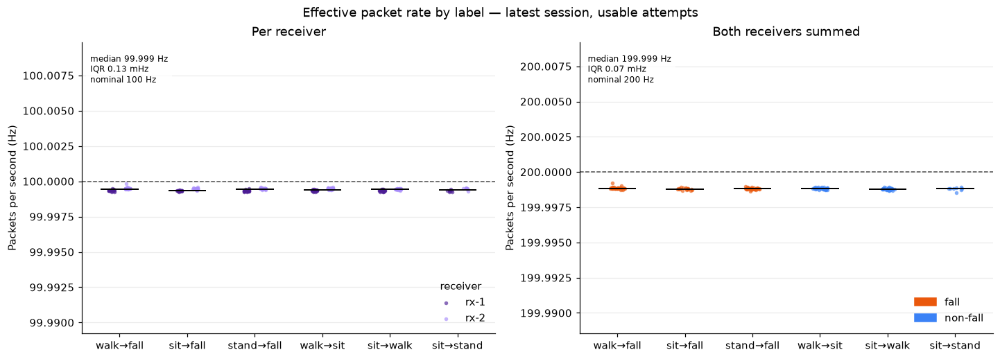

In [14]:
def padded_limits(values, pad_fraction=0.25, minimum_pad=0.01):
    values = np.asarray(values, dtype="float64")
    values = values[np.isfinite(values)]
    low, high = float(values.min()), float(values.max())
    pad = max((high - low) * pad_fraction, minimum_pad)
    return low - pad, high + pad


rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
positions = np.arange(len(LABEL_ORDER))

ax = axes[0]
for position, label in enumerate(LABEL_ORDER):
    subset = receiver_scope.loc[receiver_scope["label"].eq(label)]
    for receiver_id, offset in [("rx-1", -0.12), ("rx-2", 0.12)]:
        values = subset.loc[
            subset["receiver_id"].eq(receiver_id), "rate_hz"
        ].to_numpy()
        ax.scatter(
            position + offset + rng.uniform(-0.04, 0.04, len(values)),
            values,
            s=13,
            color=RX_COLORS[receiver_id],
            alpha=0.65,
            linewidths=0,
            label=receiver_id if position == 0 else None,
        )
    median = subset["rate_hz"].median()
    ax.hlines(
        median, position - 0.28, position + 0.28, color="black", linewidth=1.3, zorder=5
    )
ax.axhline(100, color="0.3", linestyle="--", linewidth=1)
ax.set_xticks(positions, [LABEL_DISPLAY[label] for label in LABEL_ORDER])
ax.set_ylabel("Packets per second (Hz)")
ax.set_title("Per receiver")
ax.set_ylim(*padded_limits(receiver_scope["rate_hz"]))
ax.grid(axis="x", visible=False)
ax.legend(title="receiver", loc="lower right", frameon=False)

ax = axes[1]
for position, label in enumerate(LABEL_ORDER):
    subset = packet_scope.loc[packet_scope["label"].eq(label)]
    values = subset["all_rx_rate_hz"].dropna().to_numpy()
    ax.scatter(
        position + rng.uniform(-0.11, 0.11, len(values)),
        values,
        s=13,
        color=CLASS_COLORS["fall" if label in FALL_LABELS else "non-fall"],
        alpha=0.65,
        linewidths=0,
    )
    median = np.median(values)
    ax.hlines(
        median, position - 0.28, position + 0.28, color="black", linewidth=1.3, zorder=5
    )
ax.axhline(200, color="0.3", linestyle="--", linewidth=1)
ax.set_xticks(positions, [LABEL_DISPLAY[label] for label in LABEL_ORDER])
ax.set_ylabel("Packets per second (Hz)")
ax.set_title("Both receivers summed")
ax.set_ylim(*padded_limits(packet_scope["all_rx_rate_hz"]))
ax.grid(axis="x", visible=False)
ax.legend(
    [
        plt.Rectangle((0, 0), 1, 1, color=CLASS_COLORS["fall"]),
        plt.Rectangle((0, 0), 1, 1, color=CLASS_COLORS["non-fall"]),
    ],
    ["fall", "non-fall"],
    loc="lower right",
    frameon=False,
)

for ax, values, nominal in [
    (axes[0], receiver_scope["rate_hz"], 100),
    (axes[1], packet_scope["all_rx_rate_hz"], 200),
]:
    values = values.dropna()
    median = values.median()
    iqr_mhz = 1000 * (values.quantile(0.75) - values.quantile(0.25))
    ax.text(
        0.02,
        0.96,
        f"median {median:.3f} Hz\nIQR {iqr_mhz:.2f} mHz\nnominal {nominal} Hz",
        transform=ax.transAxes,
        va="top",
        fontsize=8,
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )

for ax in axes:
    ax.ticklabel_format(axis="y", useOffset=False, style="plain")

fig.suptitle("Effective packet rate by label — latest session, usable attempts")
plt.show()


In [15]:
rate_checks = packet_scope.assign(
    rate_deviation_mhz=1000 * (packet_scope["all_rx_rate_hz"] - 200)
)
print(
    "Usable attempts without two receiver recordings: "
    f"{int(packet_scope['receiver_recordings'].ne(2).sum())}"
)
outside_range = int(
    (
        (packet_scope["all_rx_rate_hz"] < 199)
        | (packet_scope["all_rx_rate_hz"] > 201)
    ).sum()
)
print(f"Usable attempts outside 199–201 Hz all-rx rate: {outside_range}")
print(
    "Largest absolute all-rx deviation from 200 Hz: "
    f"{rate_checks['rate_deviation_mhz'].abs().max():.1f} mHz"
)
print(f"Shortest usable attempt: {int(packet_scope['sensing_packets_all_rx'].min()):,} packets")


Usable attempts without two receiver recordings: 0
Usable attempts outside 199–201 Hz all-rx rate: 0
Largest absolute all-rx deviation from 200 Hz: 1.5 mHz
Shortest usable attempt: 2,152 packets


In [16]:
fall_attempts = int(scope["binary_class"].eq("fall").sum())
non_fall_attempts = int(scope["binary_class"].eq("non-fall").sum())
fall_packets = int(
    packet_scope.loc[
        packet_scope["binary_class"].eq("fall"), "sensing_packets_all_rx"
    ].sum()
)
non_fall_packets = int(
    packet_scope.loc[
        packet_scope["binary_class"].eq("non-fall"), "sensing_packets_all_rx"
    ].sum()
)

summary = pd.DataFrame(
    [
        ("session", session_id),
        ("effective participant", sessions["participant_id"].iloc[0]),
        ("planned trials", f"{len(planned_trials):,}"),
        ("skipped trials", f"{len(skipped_trials):,}"),
        ("recorded attempts", f"{len(attempts):,}"),
        ("usable attempts", f"{len(scope):,}"),
        ("usable receiver recordings", f"{len(usable_receivers):,}"),
        (
            "raw CSI rows (usable, all rx)",
            f"{int(usable_receivers['raw_csi_rows'].sum()):,}",
        ),
        (
            "sensing packets (usable, all rx)",
            f"{int(usable_receivers['sensing_packets'].sum()):,}",
        ),
        ("fall attempts", f"{fall_attempts:,}"),
        ("non-fall attempts", f"{non_fall_attempts:,}"),
        ("fall sensing packets", f"{fall_packets:,}"),
        ("non-fall sensing packets", f"{non_fall_packets:,}"),
        (
            "per-receiver rate median (Hz)",
            f"{receiver_scope['rate_hz'].median():.4f}",
        ),
        (
            "both-receiver rate median (Hz)",
            f"{packet_scope['all_rx_rate_hz'].median():.4f}",
        ),
    ],
    columns=["metric", "value"],
)
display(summary)


,metric,value
0,session,20261026T174653764289Z
1,effective participant,akmal
2,planned trials,160
3,skipped trials,6
4,recorded attempts,171
5,usable attempts,154
6,usable receiver recordings,308
7,"raw CSI rows (usable, all rx)","450,324"
8,"sensing packets (usable, all rx)","439,895"
9,fall attempts,82


### Reading the Part 1 summary

- The session resolved all 160 planned trials: 154 accepted and 6 skipped. The
  171 recorded attempts include 17 retries that failed before acceptance.
- Four labels have 32 usable attempts each. `sit_to_fall` has 18 because three
  scenarios (six trials) were skipped; `sit_to_stand` has 8 because the protocol
  has four scenarios and no end direction.
- Usable data contains 439,895 sensing-link packets. Raw rows are only about 2.3%
  higher, and the sensing share is similar across labels (97.2–97.9%).
- Class balance is 82 fall vs 72 non-fall attempts, or 227,426 vs 212,469
  sensing packets. The packet split is slightly closer to even because attempt
  duration varies.
- Every usable attempt is within 1.5 mHz of the nominal all-receiver rate:
  199.9988 Hz on average, versus 99.9994 Hz per receiver.
- This is a single session and a single effective participant (`akmal` per the
  review sidecar; the manifest says `lano`). It cannot establish generalisation
  across people or sessions.

**Not in Part 1:** packet counts per phase, windowing, and model readiness.
Part 2 looks at raw CSI amplitude, raw phase, and calibrated phase for one example
pair; later parts can quantify separability across the dataset.


## 4. Raw CSI: fall vs non-fall, phase by phase

This section looks at the recorded CSI itself for one fall and one non-fall
attempt from the latest session. Selection is deterministic: the first usable
accepted attempt of each label with both receivers and all three phases. In this
snapshot, both selected scenarios start and end front, so the direction condition
matches. The pair is illustrative, not a statistically representative sample.

**Representation.** Each packet is decoded to its complex CSI vector. The figures
show amplitude `|CSI|`, raw wrapped phase `angle(CSI)`, and calibrated phase for
every subcarrier slot separately. The raw-phase view applies no phase calibration;
the calibrated view removes the per-packet linear trend. No subcarrier averaging,
temporal filtering, or resampling is applied in any view. The slot index is the
order in the recorded payload, not a calibrated physical-subcarrier index; null
and guard slots remain in the raw images and are masked in the calibrated image.

**Time and phases.** Host receive timestamps arrive in USB batches and repeat
across packets, so packet positions use the per-packet receiver callback clock.
That clock is shifted onto the host phase-event timeline with a median offset; the
residual is about 10 ms. Countdown, action, and recovery are reconstructed from
the host `phase_changed` events. Action can end early when the operator confirms;
recovery is reconstructed to the attempt end, so its observed duration includes
post-recovery operator time. The heatmap ends at the last received packet, which
can precede the attempt end.


In [17]:
PHASE_ORDER = ["countdown", "action", "recovery"]
PHASE_COLORS = {
    "countdown": "#737373",
    "action": "#d95f02",
    "recovery": "#1b9e77",
}
EXAMPLE_LABELS = {"fall": "walk_to_fall", "non-fall": "walk_to_sit"}


def attempt_phase_intervals(attempt_meta: dict, attempt_number: int) -> pd.DataFrame:
    # Reconstruct observed phase intervals from phase_changed events.
    rows = events.loc[
        events["kind"].eq("phase_changed")
        & events["trial_ordinal"].eq(attempt_meta["trial_ordinal"])
        & events["attempt"].eq(attempt_number)
    ].sort_values("monotonic_ns")
    if rows.empty:
        return pd.DataFrame(columns=["phase", "start_s", "end_s", "duration_s"])

    started_ns = attempt_meta["started_monotonic_ns"]
    ended_ns = attempt_meta.get("ended_monotonic_ns")
    if ended_ns is None:
        ended_ns = rows["monotonic_ns"].iloc[-1]

    interval_records = []
    for index, row in enumerate(rows.itertuples(index=False)):
        start_ns = row.monotonic_ns
        if index + 1 < len(rows):
            end_ns = rows["monotonic_ns"].iloc[index + 1]
        else:
            end_ns = ended_ns
        interval_records.append(
            {
                "phase": row.state,
                "start_s": (start_ns - started_ns) / 1e9,
                "end_s": (end_ns - started_ns) / 1e9,
                "duration_s": (end_ns - start_ns) / 1e9,
            }
        )
    return pd.DataFrame(interval_records)


selected_examples = {}
for example_kind, label in EXAMPLE_LABELS.items():
    candidates = scope.loc[scope["label"].eq(label)].sort_values(
        ["trial_ordinal", "attempt_key"]
    )
    for candidate in candidates.itertuples(index=False):
        attempt_dir = SESSION_DIR / candidate.attempt_relpath
        attempt_meta = read_json(attempt_dir / "attempt.json")
        attempt_number = int(candidate.attempt_key.rsplit("/", 1)[-1])
        intervals = attempt_phase_intervals(attempt_meta, attempt_number)
        receiver_ids = set(
            receivers.loc[
                receivers["attempt_key"].eq(candidate.attempt_key), "receiver_id"
            ]
        )
        has_all_phases = (
            len(intervals) == len(PHASE_ORDER)
            and set(intervals["phase"]) == set(PHASE_ORDER)
        )
        if has_all_phases and receiver_ids == {"rx-1", "rx-2"}:
            selected_examples[example_kind] = {
                "label": label,
                "attempt_key": candidate.attempt_key,
                "attempt_relpath": candidate.attempt_relpath,
                "scenario_id": candidate.scenario_id,
                "trial_ordinal": candidate.trial_ordinal,
                "attempt_number": attempt_number,
                "started_ns": attempt_meta["started_monotonic_ns"],
                "ended_ns": attempt_meta["ended_monotonic_ns"],
                "intervals": intervals,
            }
            break
    if example_kind not in selected_examples:
        raise ValueError(f"No complete example found for {label}")


example_table = pd.DataFrame(
    [
        {
            "example": example_kind,
            "label": example["label"],
            "scenario_id": example["scenario_id"],
            "attempt_key": example["attempt_key"],
            "attempt_duration_s": (
                example["ended_ns"] - example["started_ns"]
            )
            / 1e9,
        }
        for example_kind, example in selected_examples.items()
    ]
)
display(example_table.round(3))

planned_phases = {
    phase: protocol.get("defaults", {}).get(f"{phase}_seconds")
    for phase in PHASE_ORDER
}
phase_table = pd.concat(
    [
        example["intervals"].assign(
            example=example_kind,
            attempt_key=example["attempt_key"],
        )
        for example_kind, example in selected_examples.items()
    ],
    ignore_index=True,
)
phase_table["planned_s"] = phase_table["phase"].map(planned_phases)
phase_table = phase_table[
    [
        "example",
        "attempt_key",
        "phase",
        "start_s",
        "end_s",
        "duration_s",
        "planned_s",
    ]
]
display(phase_table.round(3))
print(
    "Selected examples are the first usable accepted attempt of each label "
    "with both receivers and all three phases."
)


,example,label,scenario_id,attempt_key,attempt_duration_s
0,fall,walk_to_fall,walk-to-fall__start_front__end_front,20261026T174653764289Z/001/01,16.621
1,non-fall,walk_to_sit,walk-to-sit__start_front__end_front,20261026T174653764289Z/089/01,16.489


,example,attempt_key,phase,start_s,end_s,duration_s,planned_s
0,fall,20261026T174653764289Z/001/01,countdown,0.001,5.075,5.074,5
1,fall,20261026T174653764289Z/001/01,action,5.075,8.944,3.868,8
2,fall,20261026T174653764289Z/001/01,recovery,8.944,16.621,7.677,5
3,non-fall,20261026T174653764289Z/089/01,countdown,0.004,5.024,5.020,5
4,non-fall,20261026T174653764289Z/089/01,action,5.024,10.769,5.745,8
5,non-fall,20261026T174653764289Z/089/01,recovery,10.769,16.489,5.720,5


Selected examples are the first usable accepted attempt of each label with both receivers and all three phases.


In [18]:
def load_csi_view(
    attempt_relpath: str,
    receiver_id: str,
    transmitter_mac: str,
    started_ns: int,
) -> dict:
    # Decode every sensing-link packet, preserving all subcarrier slots.
    receiver_dir = SESSION_DIR / attempt_relpath / "receivers" / receiver_id
    csi = pd.read_csv(
        receiver_dir / "csi.csv",
        usecols=["id", "mac", "sig_mode", "len", "first_word", "data"],
    )
    timing = pd.read_csv(
        receiver_dir / "radio_timing.csv",
        usecols=[
            "sequence",
            "host_receive_monotonic_ns",
            "rx_callback_timestamp_us",
        ],
    )

    sensing_mask = (
        csi["mac"].str.lower().eq(transmitter_mac)
        & csi["sig_mode"].eq(4)
    )
    csi = csi.loc[sensing_mask].copy()

    rx_by_sequence = timing.set_index("sequence")["rx_callback_timestamp_us"]
    host_by_sequence = timing.set_index("sequence")["host_receive_monotonic_ns"]
    csi["rx_us"] = csi["id"].map(rx_by_sequence)
    csi["host_ns"] = csi["id"].map(host_by_sequence)
    csi = (
        csi.dropna(subset=["rx_us", "host_ns"])
        .sort_values("rx_us")
        .reset_index(drop=True)
    )

    lengths = csi["len"].to_numpy(dtype=int)
    unique_lengths = np.unique(lengths)
    if len(unique_lengths) != 1:
        raise ValueError(
            f"Mixed CSI lengths in {attempt_relpath}/{receiver_id}: "
            f"{unique_lengths}"
        )

    values = np.asarray(
        [json.loads(text) for text in csi["data"]], dtype="float64"
    )
    if values.shape[1] != int(unique_lengths[0]):
        raise ValueError(
            f"Declared CSI length does not match payload in "
            f"{attempt_relpath}/{receiver_id}"
        )

    imaginary = values[:, 0::2]
    real = values[:, 1::2]
    complex_csi = real + 1j * imaginary
    complex_csi[csi["first_word"].to_numpy(dtype=int) == 1, :2] = np.nan

    rx_time_s = (
        csi["rx_us"].to_numpy(dtype="float64") - csi["rx_us"].iloc[0]
    ) / 1e6
    host_rel_s = (
        csi["host_ns"].to_numpy(dtype="float64") - started_ns
    ) / 1e9
    host_offset_s = float(np.median(host_rel_s - rx_time_s))
    time_s = rx_time_s + host_offset_s
    if np.any(np.diff(time_s) <= 0):
        raise ValueError(
            f"Non-increasing packet times in {attempt_relpath}/{receiver_id}"
        )

    return {
        "time_s": time_s,
        "amplitude": np.abs(complex_csi),
        "phase": np.angle(complex_csi),
        "complex_csi": complex_csi,
        "packets": len(csi),
        "subcarriers": complex_csi.shape[1],
        "host_offset_s": host_offset_s,
    }


csi_views = {}
for example_kind, example in selected_examples.items():
    for receiver_id in ["rx-1", "rx-2"]:
        csi_views[(example_kind, receiver_id)] = load_csi_view(
            example["attempt_relpath"],
            receiver_id,
            transmitter_mac,
            example["started_ns"],
        )

view_table = pd.DataFrame(
    [
        {
            "example": example_kind,
            "receiver": receiver_id,
            "packets": view["packets"],
            "subcarrier slots": view["subcarriers"],
            "first packet [s]": view["time_s"][0],
            "last packet [s]": view["time_s"][-1],
            "host offset [ms]": 1000 * view["host_offset_s"],
        }
        for (example_kind, receiver_id), view in csi_views.items()
    ]
)
display(view_table.round(3))


,example,receiver,packets,subcarrier slots,first packet [s],last packet [s],host offset [ms]
0,fall,rx-1,1400,245,0.001,13.991,1.109
1,fall,rx-2,1399,245,0.013,13.993,12.572
2,non-fall,rx-1,1584,245,-0.001,15.829,-1.414
3,non-fall,rx-2,1584,245,-0.002,15.828,-1.707


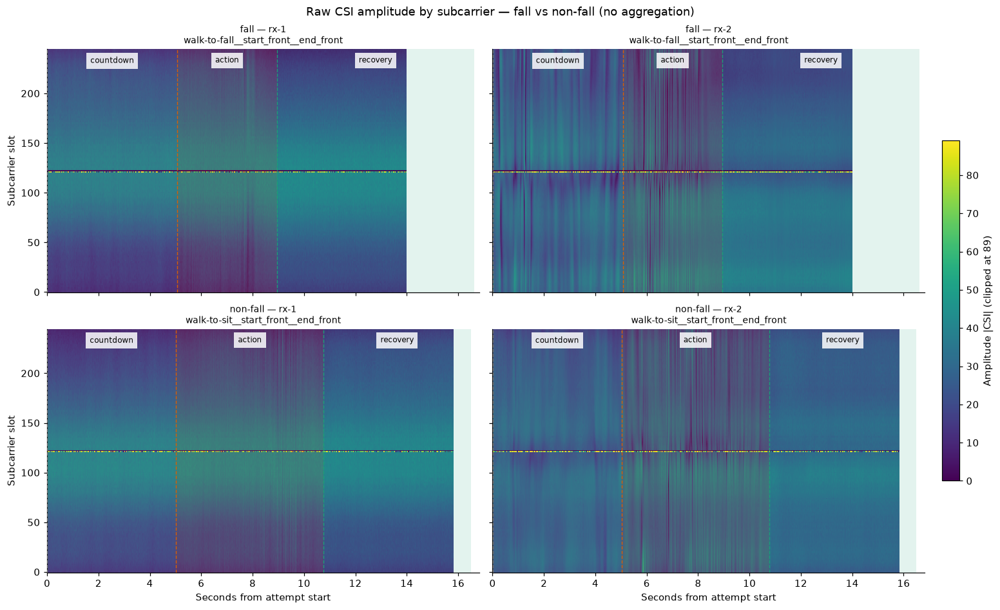

In [19]:
def add_phase_bands(ax, intervals, annotate=True):
    for row in intervals.itertuples(index=False):
        color = PHASE_COLORS[row.phase]
        ax.axvspan(
            row.start_s,
            row.end_s,
            color=color,
            alpha=0.12,
            linewidth=0,
            zorder=3,
        )
        ax.axvline(
            row.start_s,
            color=color,
            linestyle="--",
            linewidth=0.9,
            zorder=4,
        )
        if annotate:
            ax.text(
                (row.start_s + row.end_s) / 2,
                0.97,
                row.phase,
                transform=ax.get_xaxis_transform(),
                ha="center",
                va="top",
                fontsize=8,
                bbox={
                    "facecolor": "white",
                    "alpha": 0.85,
                    "edgecolor": "none",
                },
                zorder=6,
            )


amplitude_values = np.concatenate(
    [view["amplitude"].ravel() for view in csi_views.values()]
)
amplitude_vmax = float(np.nanpercentile(amplitude_values, 99.9))
plot_end_s = (
    max(
        example["intervals"]["end_s"].max()
        for example in selected_examples.values()
    )
    + 0.2
)

fig, axes = plt.subplots(
    2, 2, figsize=(14, 8.5), sharex=True, sharey=True, layout="constrained"
)
for row_index, example_kind in enumerate(["fall", "non-fall"]):
    for column_index, receiver_id in enumerate(["rx-1", "rx-2"]):
        ax = axes[row_index, column_index]
        view = csi_views[(example_kind, receiver_id)]
        mesh = ax.pcolormesh(
            view["time_s"],
            np.arange(view["subcarriers"]),
            np.ma.masked_invalid(view["amplitude"].T),
            shading="auto",
            cmap="viridis",
            vmin=0,
            vmax=amplitude_vmax,
            rasterized=True,
        )
        add_phase_bands(ax, selected_examples[example_kind]["intervals"])
        ax.set_title(
            f"{example_kind} — {receiver_id}\n"
            f"{selected_examples[example_kind]['scenario_id']}",
            fontsize=9,
        )
        ax.set_xlim(0, plot_end_s)
        ax.grid(False)
        if row_index == 1:
            ax.set_xlabel("Seconds from attempt start")
        if column_index == 0:
            ax.set_ylabel("Subcarrier slot")

fig.colorbar(
    mesh,
    ax=axes,
    shrink=0.65,
    pad=0.02,
    label=f"Amplitude |CSI| (clipped at {amplitude_vmax:.0f})",
)
fig.suptitle(
    "Raw CSI amplitude by subcarrier — fall vs non-fall (no aggregation)"
)
plt.show()


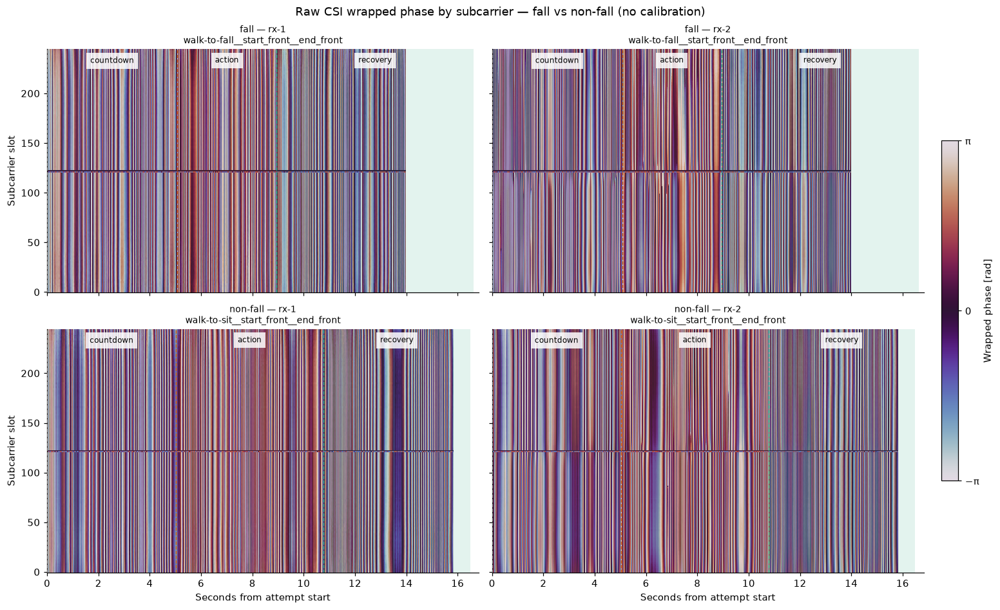

In [20]:
fig, axes = plt.subplots(
    2, 2, figsize=(14, 8.5), sharex=True, sharey=True, layout="constrained"
)
for row_index, example_kind in enumerate(["fall", "non-fall"]):
    for column_index, receiver_id in enumerate(["rx-1", "rx-2"]):
        ax = axes[row_index, column_index]
        view = csi_views[(example_kind, receiver_id)]
        mesh = ax.pcolormesh(
            view["time_s"],
            np.arange(view["subcarriers"]),
            np.ma.masked_invalid(view["phase"].T),
            shading="auto",
            cmap="twilight",
            vmin=-np.pi,
            vmax=np.pi,
            rasterized=True,
        )
        add_phase_bands(ax, selected_examples[example_kind]["intervals"])
        ax.set_title(
            f"{example_kind} — {receiver_id}\n"
            f"{selected_examples[example_kind]['scenario_id']}",
            fontsize=9,
        )
        ax.set_xlim(0, plot_end_s)
        ax.grid(False)
        if row_index == 1:
            ax.set_xlabel("Seconds from attempt start")
        if column_index == 0:
            ax.set_ylabel("Subcarrier slot")

colorbar = fig.colorbar(
    mesh,
    ax=axes,
    shrink=0.65,
    pad=0.02,
    label="Wrapped phase [rad]",
    ticks=[-np.pi, 0.0, np.pi],
)
colorbar.ax.set_yticklabels(["−π", "0", "π"])
fig.suptitle(
    "Raw CSI wrapped phase by subcarrier — fall vs non-fall (no calibration)"
)
plt.show()


### 4.1 Calibrated phase

The raw phase figure is dominated by the across-subcarrier slope and ±π wrapping.
The calibrated view applies the project's per-packet detrending:

1. Mask non-finite, null/guard, and weak (amplitude < 4) slots.
2. In ascending signed-subcarrier order, unwrap phase across frequency.
3. Fit a magnitude-weighted straight line to phase versus subcarrier index.
4. Subtract the slope and offset, then wrap the residual to `[-π, π]`.

This is the same definition as
`fall_detection.radio.preprocessing.phase.calibrate_phase`, implemented here so
the notebook remains self-contained. Calibrated phase is relative, not an
absolute phase reference: removing offset and slope can also remove motion
information. No temporal filtering or subcarrier aggregation is applied. Gray
rows are masked slots; the finite-fraction table shows how many samples remain.

The figure uses the same attempts, time axis, and phase bands as the raw phase
figure, so the two can be compared directly.


,example,receiver,packets,subcarrier slots,finite phase fraction
0,fall,rx-1,1400,245,0.984
1,fall,rx-2,1399,245,0.982
2,non-fall,rx-1,1584,245,0.984
3,non-fall,rx-2,1584,245,0.983


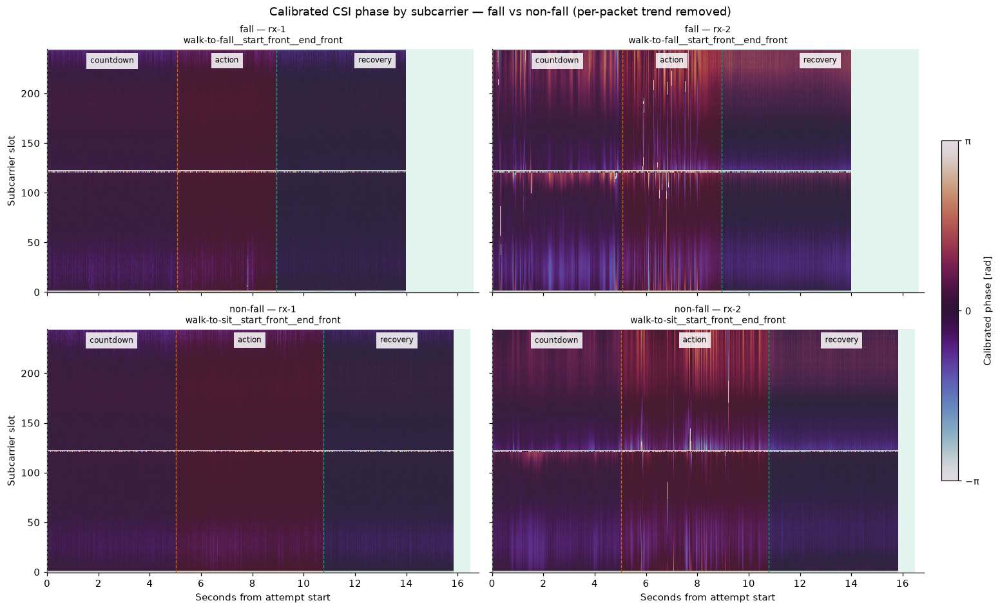

In [21]:
# Compact HE20 layout and validity set from the project's phase helper.
HE20_COMPACT_SLOT_INDICES = tuple(range(0, 123)) + tuple(range(-122, 0))
HE20_VALID_SUBCARRIERS = frozenset(
    index for index in range(-122, 123) if index not in (-1, 0, 1)
)
PHASE_AMPLITUDE_FLOOR = 4.0


def calibrate_phase_matrix(
    complex_csi: np.ndarray,
    slot_indices: tuple[int, ...],
    valid_subcarriers: frozenset[int],
    amplitude_floor: float = PHASE_AMPLITUDE_FLOOR,
) -> np.ndarray:
    # Per packet: unwrap in signed-subcarrier order, fit a magnitude-weighted
    # line, subtract it, and wrap to [-pi, pi]. Same definition as the project's
    # calibrate_phase helper.
    packet_count, slot_count = complex_csi.shape
    if slot_count != len(slot_indices):
        raise ValueError(
            f"Expected {len(slot_indices)} slots, got {slot_count}"
        )

    calibrated = np.full((packet_count, slot_count), np.nan)
    indices = np.asarray(slot_indices, dtype="float64")
    order = np.argsort(indices)
    ordered_indices = indices[order]
    ordered_csi = complex_csi[:, order]
    amplitudes = np.abs(ordered_csi)
    phases = np.angle(ordered_csi)
    valid_slots = np.array(
        [index in valid_subcarriers for index in ordered_indices], dtype=bool
    )
    valid = (
        np.isfinite(ordered_csi.real)
        & np.isfinite(ordered_csi.imag)
        & np.isfinite(amplitudes)
        & (amplitudes >= amplitude_floor)
        & valid_slots[None, :]
    )

    for packet_index in range(packet_count):
        packet_valid = valid[packet_index]
        if packet_valid.sum() < 3:
            continue
        fit_indices = ordered_indices[packet_valid]
        fit_phases = np.unwrap(phases[packet_index, packet_valid])
        weights = np.maximum(
            amplitudes[packet_index, packet_valid], amplitude_floor
        )
        design = np.column_stack(
            (fit_indices, np.ones(fit_indices.shape))
        )
        weighted_design = design * np.sqrt(weights)[:, None]
        weighted_phases = fit_phases * np.sqrt(weights)
        slope, offset = np.linalg.lstsq(
            weighted_design, weighted_phases, rcond=None
        )[0]
        residual = (
            fit_phases - (slope * fit_indices + offset) + np.pi
        ) % (2 * np.pi) - np.pi
        calibrated[packet_index, packet_valid] = residual

    calibrated_original_order = np.full_like(calibrated, np.nan)
    calibrated_original_order[:, order] = calibrated
    return calibrated_original_order


calibrated_phase = {}
for key, view in csi_views.items():
    calibrated_phase[key] = calibrate_phase_matrix(
        view["complex_csi"],
        HE20_COMPACT_SLOT_INDICES,
        HE20_VALID_SUBCARRIERS,
    )

calibration_table = pd.DataFrame(
    [
        {
            "example": example_kind,
            "receiver": receiver_id,
            "packets": view["packets"],
            "subcarrier slots": view["subcarriers"],
            "finite phase fraction": np.isfinite(
                calibrated_phase[(example_kind, receiver_id)]
            ).mean(),
        }
        for (example_kind, receiver_id), view in csi_views.items()
    ]
)
display(calibration_table.round(4))

calibrated_cmap = plt.get_cmap("twilight").copy()
calibrated_cmap.set_bad("0.85")

fig, axes = plt.subplots(
    2, 2, figsize=(14, 8.5), sharex=True, sharey=True, layout="constrained"
)
for row_index, example_kind in enumerate(["fall", "non-fall"]):
    for column_index, receiver_id in enumerate(["rx-1", "rx-2"]):
        ax = axes[row_index, column_index]
        view = csi_views[(example_kind, receiver_id)]
        mesh = ax.pcolormesh(
            view["time_s"],
            np.arange(view["subcarriers"]),
            np.ma.masked_invalid(
                calibrated_phase[(example_kind, receiver_id)].T
            ),
            shading="auto",
            cmap=calibrated_cmap,
            vmin=-np.pi,
            vmax=np.pi,
            rasterized=True,
        )
        add_phase_bands(ax, selected_examples[example_kind]["intervals"])
        ax.set_title(
            f"{example_kind} — {receiver_id}\n"
            f"{selected_examples[example_kind]['scenario_id']}",
            fontsize=9,
        )
        ax.set_xlim(0, plot_end_s)
        ax.grid(False)
        if row_index == 1:
            ax.set_xlabel("Seconds from attempt start")
        if column_index == 0:
            ax.set_ylabel("Subcarrier slot")

colorbar = fig.colorbar(
    mesh,
    ax=axes,
    shrink=0.65,
    pad=0.02,
    label="Calibrated phase [rad]",
    ticks=[-np.pi, 0.0, np.pi],
)
colorbar.ax.set_yticklabels(["−π", "0", "π"])
fig.suptitle(
    "Calibrated CSI phase by subcarrier — fall vs non-fall "
    "(per-packet trend removed)"
)
plt.show()


The two examples are illustrative. The fall action is shorter (3.87 s) than the
walk-to-sit action (5.75 s), so compare each action band with its own countdown
and recovery rather than with equal-length slices. The amplitude scale is shared
across all four panels and clipped at the 99.9th percentile; both phase scales are
fixed to `[-π, π]`. Null and guard slots remain in the raw images and are masked
in the calibrated image.

The amplitude panels are the more readable raw view. In this pair, the fall action
band is shorter and contains a sharper, more localized disturbance, while the
walk-to-sit action shows a longer sequence of stripes. That is a description of
these two attempts, not a class difference.

The raw phase panel is dominated by the across-subcarrier slope and ±π wrapping.
The calibrated panel removes the per-packet magnitude-weighted linear trend and
masks null/guard/weak slots; it is smoother and easier to compare across
subcarriers. At rx-2 the action disturbance is clearer; at rx-1 it is subtle.
Calibration is relative and can remove motion information, so this is a
representation choice, not evidence that calibrated phase is better.

Both phase views are unaggregated: every displayed row is one subcarrier slot.
The blank tail after the last packet is outside the receiver stream, not zero
CSI. Recovery is drawn to the attempt end; the planned recovery is 5 s, and the
CSI stream ends near that planned boundary.

This pair shows what the data looks like; it is not evidence that fall and
non-fall classes separate. Quantifying that needs multiple attempts, receivers,
participants, and sessions in later parts.


## 5. Phase-motion traces and trial-level bursts

The heatmaps above show two examples. This section asks whether a short, strong
phase disturbance recurs across fall attempts and differs from non-fall movement.
It includes every usable attempt with complete countdown/action/recovery events.
The all-label plots describe activity families separately; a second comparison
matches `walk_to_fall` and `walk_to_sit` by starting and ending direction.

For each packet, the motion score is the median absolute circular phase change
across eligible subcarriers at approximately 100 ms:

$$M(t)=\operatorname{median}_k\left|\arg\exp\{j[\phi_k(t)-\phi_k(t-0.1)]\}\right|.$$

The shared loader uses the physical HE-LTF decoder, masks invalid/null/guard/weak
tones, and selects the same countdown-eligible tones for raw and calibrated
phase. It uses receiver callback timestamps mapped through the recorded USB
affine clock fit; the diagnostics identify any host-receive fallback. This is a
more precise event alignment than the median-offset illustration in section 4.
Scores require at least half the eligible tones and at least three tones.
Actual lag must be at most 150 ms. Lag endpoints must be in the same phase.
No temporal filtering or trace resampling is applied.

Each recording and representation gets its own **countdown 95th-percentile
threshold**. This is an exploratory background reference, not a fitted fall
threshold. It allows about 5% of countdown observations above threshold when
there are no ties. A burst is a contiguous run of action scores strictly above
that reference. Missing scores or inter-packet gaps above 50 ms break a run.

In [22]:
import hashlib
import sys

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from fall_detection.analysis.phase_motion import load_phase_motion_samples
from fall_detection.analysis.phase_bursts import summarize_phase_bursts

MOTION_LAG_SECONDS = 0.1
MOTION_BASELINE_SECONDS = 1.0  # First countdown second selects eligible tones.
BURST_THRESHOLD_QUANTILE = 0.95  # All valid countdown scores set the threshold.
MIN_PHASE_SCORES = 20
MAX_BURST_GAP_SECONDS = 0.05
RECOVERY_WINDOW_SECONDS = 1.0
MOTION_WORKERS = 4
TRACE_REPRESENTATION = "calibrated"  # Change to "raw" to inspect its full traces.
BURST_LABELS = LABEL_ORDER  # Can be restricted before rerunning this section.
BURST_SEED = 0  # Reproducible point jitter only; no model is fitted.

BURST_OUTPUT_DIR = ROOT / "data/interim/simple-eda" / session_id
BURST_FIGURE_DIR = ROOT / "docs/figures/simple-eda" / session_id
BURST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BURST_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SCORE_COLUMNS = {"raw": "raw_score", "calibrated": "calibrated_score"}

In [23]:
scenario_attributes = {
    scenario["id"]: scenario.get("attributes", {})
    for block in protocol.get("blocks", [])
    for scenario in block.get("scenarios", [])
}
motion_metadata, motion_interval_rows, motion_exclusions = [], [], []
motion_bounds = {}
for candidate in scope.loc[scope["label"].isin(BURST_LABELS)].itertuples(index=False):
    metadata = read_json(SESSION_DIR / candidate.attempt_relpath / "attempt.json")
    number = int(candidate.attempt_key.rsplit("/", 1)[-1])
    intervals = attempt_phase_intervals(metadata, number)
    complete = (
        len(intervals) == 3 and list(intervals["phase"]) == PHASE_ORDER
        and intervals["duration_s"].gt(0).all()
    )
    if not complete:
        motion_exclusions.append({"attempt_key": candidate.attempt_key,
                                  "reason": "incomplete or unordered phase events"})
        continue
    attempt_id = "/".join(candidate.attempt_key.split("/")[-2:])
    attrs = scenario_attributes.get(candidate.scenario_id, {})
    motion_metadata.append({
        "attempt_id": attempt_id, "attempt_key": candidate.attempt_key,
        "attempt_relpath": candidate.attempt_relpath,
        "label": str(candidate.label), "binary_class": candidate.binary_class,
        "scenario_id": candidate.scenario_id,
        "start_direction": attrs.get("start_direction", "unknown"),
        "end_direction": attrs.get("end_direction", "unknown"),
    })
    motion_bounds[attempt_id] = {
        row.phase: (row.start_s, row.end_s)
        for row in intervals.itertuples(index=False)
    }
    for row in intervals.itertuples(index=False):
        motion_interval_rows.append({
            "attempt_id": attempt_id, "phase": row.phase,
            "phase_start_monotonic_ns": metadata["started_monotonic_ns"]
                + round(row.start_s * 1e9),
            "phase_end_monotonic_ns": metadata["started_monotonic_ns"]
                + round(row.end_s * 1e9),
        })

motion_metadata = pd.DataFrame(motion_metadata)
if motion_metadata.empty:
    raise ValueError("No usable attempts have all three phase intervals")
motion_result = load_phase_motion_samples(
    SESSION_DIR, motion_metadata["attempt_id"].tolist(), list(RX_COLORS),
    pd.DataFrame(motion_interval_rows),
    baseline_seconds=MOTION_BASELINE_SECONDS, lag_seconds=MOTION_LAG_SECONDS,
    cache_dir=ROOT / "data/interim/phase-motion", workers=MOTION_WORKERS,
)
motion_samples = motion_result.samples
motion_diagnostics = motion_result.recordings
print(f"Eligible attempts: {len(motion_metadata)}; excluded phase events: {len(motion_exclusions)}")
print(f"Receiver recordings requested: {len(motion_diagnostics)}")
print(f"Read failures: {motion_diagnostics['read_error'].ne('').sum()}")
print(f"Cached recordings reused: {motion_diagnostics['cache_hit'].sum()}")
display(motion_diagnostics.groupby("time_source", dropna=False).size().rename("recordings").to_frame()
        if "time_source" in motion_diagnostics else motion_diagnostics)
if motion_exclusions:
    display(pd.DataFrame(motion_exclusions))
if motion_diagnostics["read_error"].ne("").any():
    display(motion_diagnostics.loc[motion_diagnostics["read_error"].ne("")])

Eligible attempts: 154; excluded phase events: 0
Receiver recordings requested: 308
Read failures: 0
Cached recordings reused: 308


,recordings
time_source,
receiver callback → host (USB affine fit),308


### 5.1 Measurements and coverage

One row below is one attempt, receiver, and representation. Usability requires
at least 20 finite countdown and action scores plus positive action time support.
This is a pilot coverage rule, not a training acceptance criterion. Recovery
measurements need at least 20 scores in the first second of recovery; otherwise
they remain missing. The initial 100 ms of each phase lacks within-phase scores.

| Measurement | Definition |
| --- | --- |
| Action p95 excess [rad] | Action 95th percentile minus countdown threshold; negative values are retained. |
| Peak excess [rad] | Action maximum minus countdown threshold. |
| Longest burst [s] | Longest observed above-threshold run, from first to last sample. |
| Active fraction | Above-threshold supported duration divided by all supported action duration. |
| Rise 10–90% [s] | Interpolated rise of excess over threshold within the burst containing the action maximum. Missing when its beginning is unobserved. |
| Recovery median excess [rad] | Median in the first recovery second minus countdown median. |

Supported duration sums adjacent finite score intervals separated by at most
50 ms. Above-threshold duration requires both endpoints above threshold, so it
is a lower bound; a single high sample contributes zero duration. No gap is
filled with stationary values. Coverage and peak-burst censoring flags remain
in the CSV. Raw and calibrated measurements retain separate countdown references.

In [24]:
feature_rows = []
for (attempt_id, receiver_id), samples in motion_samples.groupby(
    ["attempt_id", "receiver_id"], sort=True
):
    samples = samples.sort_values("seconds")
    for representation, column in SCORE_COLUMNS.items():
        scores = samples[column].where(samples["within_phase_lag"]).to_numpy()
        measurements = summarize_phase_bursts(
            samples["seconds"].to_numpy(), scores, motion_bounds[attempt_id],
            threshold_quantile=BURST_THRESHOLD_QUANTILE,
            min_phase_scores=MIN_PHASE_SCORES,
            max_gap_seconds=MAX_BURST_GAP_SECONDS,
            recovery_window_seconds=RECOVERY_WINDOW_SECONDS,
        )
        feature_rows.append({"attempt_id": attempt_id, "receiver_id": receiver_id,
                             "representation": representation, **measurements})

burst_features = pd.DataFrame(feature_rows)
if burst_features.empty:
    raise ValueError("No receiver traces could be measured; inspect read failures")
burst_features = burst_features.merge(
    motion_metadata, on="attempt_id", validate="many_to_one"
)
burst_features["label"] = pd.Categorical(
    burst_features["label"], categories=LABEL_ORDER, ordered=True
)
usable_bursts = burst_features.loc[burst_features["usable"]].copy()
if usable_bursts.empty:
    raise ValueError("No traces satisfy the countdown/action coverage rule")

coverage = burst_features.groupby(
    ["label", "receiver_id", "representation"], observed=True
).agg(
    measured_attempts=("attempt_id", "nunique"), usable_attempts=("usable", "sum"),
    median_action_support=("action_supported_fraction", "median"),
    observed_rises=("rise_10_90_s", "count"),
    observed_recovery=("recovery_median_excess_rad", "count"),
)
display(coverage)
print("Unavailable source files remain in recording diagnostics; sparse traces remain in the feature CSV.")

burst_metrics = ["action_p95_excess_rad", "longest_burst_s", "active_fraction",
                 "rise_10_90_s", "recovery_median_excess_rad"]
burst_summary = usable_bursts.groupby(
    ["receiver_id", "representation", "label"], observed=True
)[burst_metrics].median()
display(burst_summary)

measured_attempts  usable_attempts  median_action_support  observed_rises  observed_recovery
label         receiver_id representation                                                                                              
walk_to_fall  rx-1        calibrated                     32               32                  0.974              31                 32
                          raw                            32               32                  0.974              32                 32
              rx-2        calibrated                     32               32                  0.975              29                 32
                          raw                            32               32                  0.975              31                 32
sit_to_fall   rx-1        calibrated                     18               18                  0.973              18                 18
                          raw                            18               18                  0.973              18                 18
              rx-2        calibrated                     18               18                  0.973              18                 18
                          raw                            18               18                  0.973              18                 18
stand_to_fall rx-1        calibrated                     32               32                  0.964              32                 32
                          raw                            32               32                  0.964              32                 32
              rx-2        calibrated                     32               32                  0.964              32                 32
                          raw                            32               32                  0.964              32                 32
walk_to_sit   rx-1        calibrated                     32               32                  0.981              31                 32
                          raw                            32               32                  0.981              31                 32
              rx-2        calibrated                     32               32                  0.980              32                 32
                          raw                            32               32                  0.980              32                 32
sit_to_walk   rx-1        calibrated                     32               32                  0.973              32                 32
                          raw                            32               32                  0.973              32                 32
              rx-2        calibrated                     32               32                  0.972              31                 32
                          raw                            32               32                  0.972              32                 32
sit_to_stand  rx-1        calibrated                      8                8                  0.963               8                  8
                          raw                             8                8                  0.963               8                  8
              rx-2        calibrated                      8                8                  0.962               8                  8
                          raw                             8                8                  0.962               8                  8

Unavailable source files remain in recording diagnostics; sparse traces remain in the feature CSV.


action_p95_excess_rad  longest_burst_s  active_fraction  rise_10_90_s  recovery_median_excess_rad
receiver_id representation label                                                                                                           
rx-1        calibrated     walk_to_fall                   0.008            0.010            0.009         0.006                      -0.002
                           sit_to_fall                    0.005            0.010            0.005         0.005                       0.000
                           stand_to_fall                 -0.000            0.010            0.003         0.004                      -0.000
                           walk_to_sit                   -0.000            0.010            0.004         0.006                      -0.003
                           sit_to_walk                    0.001            0.010            0.003         0.005                       0.002
                           sit_to_stand                   0.002            0.010            0.005         0.006                      -0.003
            raw            walk_to_fall                   0.003            0.010            0.011         0.003                      -0.009
                           sit_to_fall                    0.011            0.010            0.015         0.004                       0.074
                           stand_to_fall                 -0.028            0.010            0.010         0.002                      -0.043
                           walk_to_sit                    0.011            0.020            0.012         0.003                       0.101
                           sit_to_walk                    0.011            0.015            0.017         0.003                       0.021
                           sit_to_stand                  -0.052            0.010            0.006         0.001                       0.159
rx-2        calibrated     walk_to_fall                   0.031            0.030            0.036         0.007                      -0.021
                           sit_to_fall                    0.024            0.030            0.031         0.008                       0.001
                           stand_to_fall                  0.025            0.020            0.019         0.007                      -0.035
                           walk_to_sit                    0.017            0.030            0.022         0.012                      -0.020
                           sit_to_walk                    0.114            0.060            0.080         0.013                       0.026
                           sit_to_stand                   0.560            0.165            0.242         0.017                       0.036
            raw            walk_to_fall                  -0.010            0.015            0.007         0.005                       0.052
                           sit_to_fall                   -0.008            0.015            0.008         0.003                       0.100
                           stand_to_fall                 -0.027            0.020            0.009         0.004                       0.147
                           walk_to_sit                   -0.001            0.020            0.012         0.003                       0.159
                           sit_to_walk                   -0.066            0.020            0.006         0.003                       0.007
                           sit_to_stand                  -0.094            0.010            0.004         0.001                      -0.005

### 5.2 The illustrative pair as motion traces

These are the same two attempts as section 4. Both traces are aligned to their
own action cue at zero. Dashed horizontal lines show their countdown thresholds;
dotted vertical lines mark their respective recovery cues. The timing uses the
shared affine-fit loader described above. Raw and calibrated panels have
independent scales. A disturbance may reflect motion or residual radio effects;
a high score alone does not identify a fall.

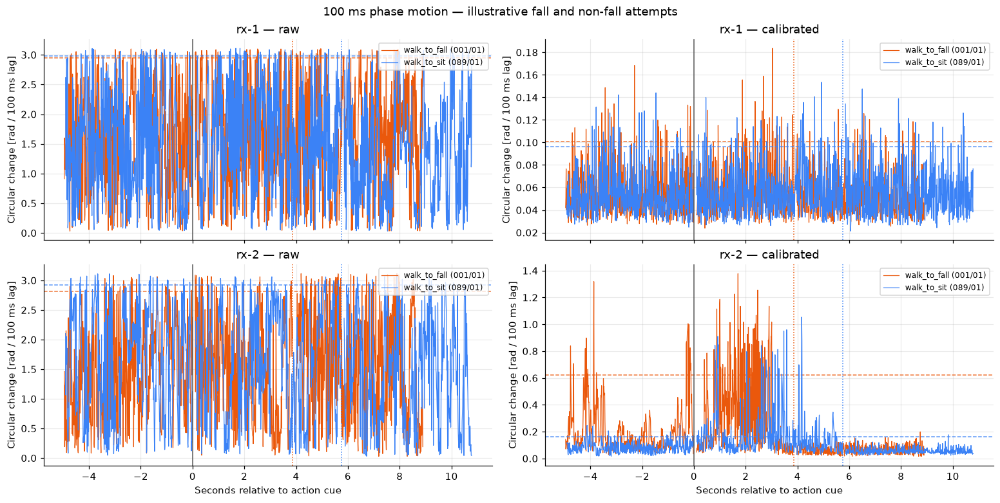

In [25]:
def motion_plot_values(samples: pd.DataFrame, column: str) -> np.ndarray:
    # Break plotted lines at invalid phase lags and unsupported timestamp gaps.
    values = samples[column].where(samples["within_phase_lag"]).to_numpy().copy()
    gaps = np.r_[False, np.diff(samples["seconds"]) > MAX_BURST_GAP_SECONDS]
    values[gaps] = np.nan
    return values


fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, layout="constrained")
for row, receiver_id in enumerate(RX_COLORS):
    for col, (representation, score_column) in enumerate(SCORE_COLUMNS.items()):
        ax = axes[row, col]
        for kind, example in selected_examples.items():
            attempt_id = "/".join(example["attempt_key"].split("/")[-2:])
            samples = motion_samples.loc[
                motion_samples["attempt_id"].eq(attempt_id)
                & motion_samples["receiver_id"].eq(receiver_id)
            ].sort_values("seconds")
            if samples.empty:
                continue
            bounds = motion_bounds[attempt_id]
            ax.plot(samples["seconds"] - bounds["action"][0],
                    motion_plot_values(samples, score_column),
                    color=CLASS_COLORS[kind], lw=0.8,
                    label=f"{example['label']} ({attempt_id})")
            feature = burst_features.loc[
                burst_features["attempt_id"].eq(attempt_id)
                & burst_features["receiver_id"].eq(receiver_id)
                & burst_features["representation"].eq(representation)
            ].iloc[0]
            if np.isfinite(feature["threshold_rad"]):
                ax.axhline(feature["threshold_rad"], color=CLASS_COLORS[kind],
                           ls="--", lw=1, alpha=0.8)
            ax.axvline(bounds["recovery"][0] - bounds["action"][0],
                       color=CLASS_COLORS[kind], ls=":", lw=1)
        ax.axvline(0, color="0.35", lw=1)
        ax.set_title(f"{receiver_id} — {representation}")
        ax.set_ylabel("Circular change [rad / 100 ms lag]")
        ax.legend(fontsize=8)
        if row == 1:
            ax.set_xlabel("Seconds relative to action cue")
fig.suptitle("100 ms phase motion — illustrative fall and non-fall attempts")
fig.savefig(BURST_FIGURE_DIR / "example-motion-traces.png", dpi=150)
plt.show()

### 5.3 Repeated attempts on the same time axis

Each faint line is a usable attempt for the displayed receiver and
representation. Zero on the horizontal axis is the action cue; zero vertically
is that recording's countdown threshold. The view includes two seconds before
and eight seconds after the cue, without stretching the action durations.
Recovery starts at a different time in each attempt and is included when
recorded. These are cue-aligned trajectories, not impact-aligned averages.

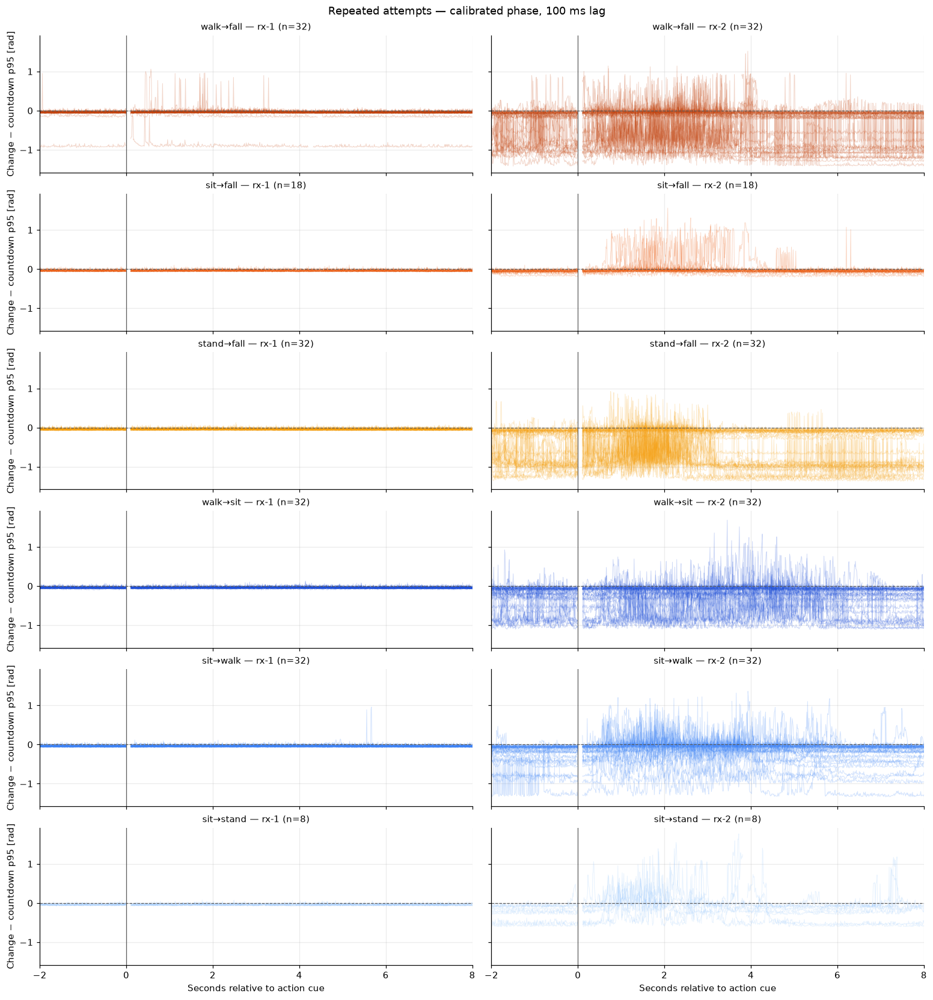

In [26]:
trace_labels = [label for label in LABEL_ORDER if label in set(usable_bursts["label"])]
fig, axes = plt.subplots(len(trace_labels), 2, figsize=(14, 2.5 * len(trace_labels)),
                         sharex=True, sharey=True, squeeze=False, layout="constrained")
trace_column = SCORE_COLUMNS[TRACE_REPRESENTATION]
for row, label in enumerate(trace_labels):
    for col, receiver_id in enumerate(RX_COLORS):
        ax = axes[row, col]
        selected = usable_bursts.loc[
            usable_bursts["label"].eq(label)
            & usable_bursts["receiver_id"].eq(receiver_id)
            & usable_bursts["representation"].eq(TRACE_REPRESENTATION)
        ]
        for feature in selected.itertuples(index=False):
            samples = motion_samples.loc[
                motion_samples["attempt_id"].eq(feature.attempt_id)
                & motion_samples["receiver_id"].eq(receiver_id)
            ].sort_values("seconds")
            ax.plot(samples["seconds"] - motion_bounds[feature.attempt_id]["action"][0],
                    motion_plot_values(samples, trace_column) - feature.threshold_rad,
                    color=LABEL_COLORS[label], alpha=0.22, lw=0.65)
        ax.axhline(0, color="0.35", ls="--", lw=0.8)
        ax.axvline(0, color="0.35", lw=0.8)
        ax.set_xlim(-2, 8)
        ax.set_title(f"{LABEL_DISPLAY[label]} — {receiver_id} (n={len(selected)})", fontsize=10)
        if col == 0:
            ax.set_ylabel("Change − countdown p95 [rad]")
        if row == len(trace_labels) - 1:
            ax.set_xlabel("Seconds relative to action cue")
fig.suptitle(f"Repeated attempts — {TRACE_REPRESENTATION} phase, 100 ms lag")
fig.savefig(BURST_FIGURE_DIR / f"all-motion-traces-{TRACE_REPRESENTATION}.png", dpi=150)
plt.show()

### 5.4 Feature overlap and direction-matched walking comparison

The points below give equal visual weight to each attempt. Black bars mark
activity medians. The rise-time table above reports only observable rises;
missing or left-censored rises are not zero. The direction-matched table then
compares walking activities within each start/end direction: first take the
median across repetitions, then subtract the sitting median from the falling
median. Only direction conditions containing both activities are retained.
There are no independent receiver replicates and no held-out evaluation here.

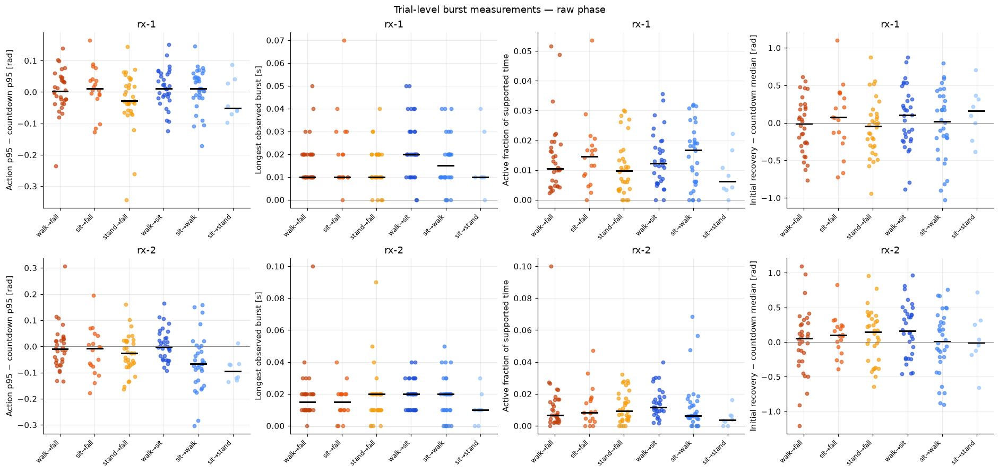

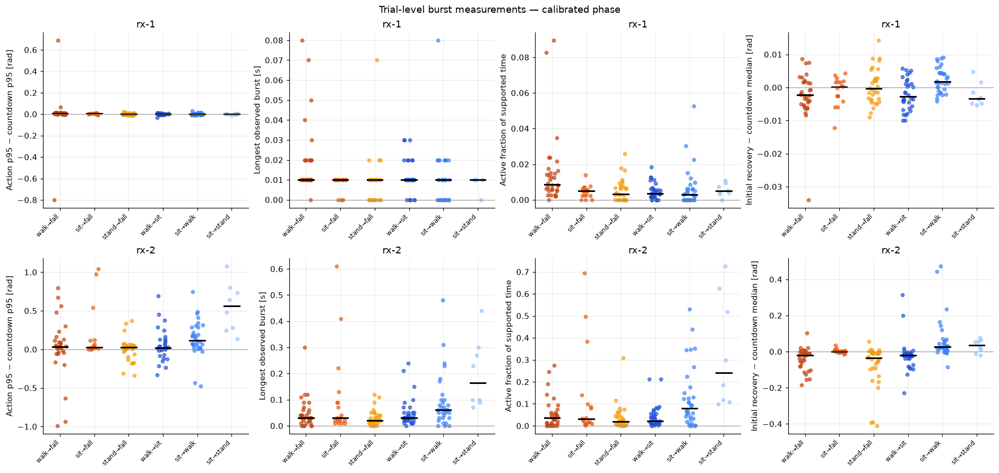

direction_conditions  median_fall_minus_sit    q25    q75
receiver_id representation metric                                                                               
rx-1        calibrated     action_p95_excess_rad                         16                  0.006  0.001  0.011
                           active_fraction                               16                  0.008  0.004  0.013
                           longest_burst_s                               16                  0.005 -0.001  0.015
                           recovery_median_excess_rad                    16                  0.000 -0.003  0.003
                           rise_10_90_s                                  16                  0.000 -0.001  0.004
            raw            action_p95_excess_rad                         16                  0.003 -0.036  0.052
                           active_fraction                               16                  0.001 -0.002  0.006
                           longest_burst_s                               16                 -0.005 -0.020  0.001
                           recovery_median_excess_rad                    16                 -0.010 -0.328  0.146
                           rise_10_90_s                                  16                  0.001 -0.001  0.001
rx-2        calibrated     action_p95_excess_rad                         16                  0.037 -0.200  0.161
                           active_fraction                               16                  0.009 -0.021  0.058
                           longest_burst_s                               16                 -0.008 -0.026  0.015
                           recovery_median_excess_rad                    16                 -0.008 -0.058  0.033
                           rise_10_90_s                                  16                 -0.007 -0.012 -0.001
            raw            action_p95_excess_rad                         16                 -0.025 -0.046  0.030
                           active_fraction                               16                 -0.004 -0.009  0.001
                           longest_burst_s                               16                 -0.000 -0.006  0.000
                           recovery_median_excess_rad                    16                 -0.191 -0.386  0.089
                           rise_10_90_s                                  16                  0.001 -0.002  0.002

Differences are descriptive, with one value per matched direction condition.


In [27]:
plot_metrics = {
    "action_p95_excess_rad": "Action p95 − countdown p95 [rad]",
    "longest_burst_s": "Longest observed burst [s]",
    "active_fraction": "Active fraction of supported time",
    "recovery_median_excess_rad": "Initial recovery − countdown median [rad]",
}
rng = np.random.default_rng(BURST_SEED)
for representation in SCORE_COLUMNS:
    fig, axes = plt.subplots(2, len(plot_metrics), figsize=(17, 8),
                             squeeze=False, layout="constrained")
    for row, receiver_id in enumerate(RX_COLORS):
        selected = usable_bursts.loc[
            usable_bursts["receiver_id"].eq(receiver_id)
            & usable_bursts["representation"].eq(representation)
        ]
        for col, (metric, ylabel) in enumerate(plot_metrics.items()):
            ax = axes[row, col]
            for pos, label in enumerate(trace_labels):
                values = selected.loc[selected["label"].eq(label), metric].dropna()
                ax.scatter(pos + rng.uniform(-0.17, 0.17, len(values)), values,
                           s=17, alpha=0.65, color=LABEL_COLORS[label])
                if len(values):
                    ax.plot([pos - 0.22, pos + 0.22], [values.median()] * 2,
                            color="black", lw=2)
            ax.set_xticks(range(len(trace_labels)),
                          [LABEL_DISPLAY[label] for label in trace_labels],
                          rotation=45, ha="right", fontsize=8)
            ax.set_ylabel(ylabel)
            ax.set_title(receiver_id)
            ax.axhline(0, color="0.5", lw=0.6)
    fig.suptitle(f"Trial-level burst measurements — {representation} phase")
    fig.savefig(BURST_FIGURE_DIR / f"burst-features-{representation}.png", dpi=150)
    plt.show()

walking = usable_bursts.loc[
    usable_bursts["label"].isin(["walk_to_fall", "walk_to_sit"])
    & usable_bursts["start_direction"].ne("unknown")
    & usable_bursts["end_direction"].ne("unknown")
]
matched_rows = []
for keys, condition in walking.groupby(
    ["receiver_id", "representation", "start_direction", "end_direction"],
    observed=True,
):
    counts = condition.groupby("label", observed=True).size()
    if not {"walk_to_fall", "walk_to_sit"}.issubset(counts.index):
        continue
    medians = condition.groupby("label", observed=True)[burst_metrics].median()
    for metric in burst_metrics:
        difference = medians.loc["walk_to_fall", metric] - medians.loc["walk_to_sit", metric]
        matched_rows.append(dict(
            zip(["receiver_id", "representation", "start_direction", "end_direction"], keys),
            metric=metric, fall_attempts=int(counts["walk_to_fall"]),
            nonfall_attempts=int(counts["walk_to_sit"]), difference=difference,
        ))
matched_differences = pd.DataFrame(matched_rows, columns=[
    "receiver_id", "representation", "start_direction", "end_direction",
    "metric", "fall_attempts", "nonfall_attempts", "difference",
])
matched_summary = matched_differences.groupby(
    ["receiver_id", "representation", "metric"], observed=True
).agg(
    direction_conditions=("difference", "count"),
    median_fall_minus_sit=("difference", "median"),
    q25=("difference", lambda values: values.quantile(0.25)),
    q75=("difference", lambda values: values.quantile(0.75)),
)
display(matched_summary)
print("Differences are descriptive, with one value per matched direction condition.")

In [28]:
burst_features.to_csv(BURST_OUTPUT_DIR / "burst-features.csv", index=False)
coverage.to_csv(BURST_OUTPUT_DIR / "coverage.csv")
burst_summary.to_csv(BURST_OUTPUT_DIR / "activity-medians.csv")
matched_differences.to_csv(BURST_OUTPUT_DIR / "matched-walking-differences.csv", index=False)
matched_summary.to_csv(BURST_OUTPUT_DIR / "matched-walking-summary.csv")
motion_diagnostics.to_csv(BURST_OUTPUT_DIR / "recording-diagnostics.csv", index=False)
pd.DataFrame(motion_exclusions, columns=["attempt_key", "reason"]).to_csv(
    BURST_OUTPUT_DIR / "excluded-phase-events.csv", index=False
)

# Pin source metadata and analysis code with the exploratory parameter choices.
source_paths = [SESSION_DIR / name for name in
                ("session.json", "protocol.json", "events.jsonl", "session_review.json")]
for relative_path in motion_metadata["attempt_relpath"]:
    attempt_dir = SESSION_DIR / relative_path
    source_paths.append(attempt_dir / "attempt.json")
    for receiver_id in RX_COLORS:
        source_paths.extend(attempt_dir / "receivers" / receiver_id / name
                            for name in ("csi.csv", "radio_timing.csv", "usb_clock_sync.csv"))
source_metadata = [
    [str(path.relative_to(ROOT)), path.stat().st_size, path.stat().st_mtime_ns]
    if path.exists() else [str(path.relative_to(ROOT)), None]
    for path in source_paths
]
code_paths = [ROOT / "src/fall_detection" / name for name in (
    "analysis/phase_motion.py", "analysis/phase_bursts.py", "analysis/phase_signals.py",
    "radio/preprocessing/phase.py", "radio/acquisition/clock_sync.py",
)]
notebook_code = "\n".join(
    "".join(cell["source"]) for cell in
    read_json(ROOT / "notebooks/02_simple_eda.ipynb")["cells"] if cell["cell_type"] == "code"
)
burst_parameters = {
    "session_id": session_id, "participant_id": effective_participant,
    "session_status": manifest.get("status"), "labels": list(BURST_LABELS),
    "lag_seconds": MOTION_LAG_SECONDS, "max_actual_lag_seconds": 1.5 * MOTION_LAG_SECONDS,
    "tone_baseline_seconds": MOTION_BASELINE_SECONDS,
    "countdown_threshold_quantile": BURST_THRESHOLD_QUANTILE,
    "min_phase_scores": MIN_PHASE_SCORES, "max_gap_seconds": MAX_BURST_GAP_SECONDS,
    "recovery_window_seconds": RECOVERY_WINDOW_SECONDS, "jitter_seed": BURST_SEED,
    "trace_representation": TRACE_REPRESENTATION,
    "source_metadata_sha256": hashlib.sha256(json.dumps(source_metadata).encode()).hexdigest(),
    "code_sha256": {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                    for path in code_paths},
    "notebook_code_sha256": hashlib.sha256(notebook_code.encode()).hexdigest(),
    "versions": {"numpy": np.__version__, "pandas": pd.__version__},
    "interpretation": "Within-session descriptive EDA; no trained detector or independent test set.",
}
(BURST_OUTPUT_DIR / "parameters.json").write_text(json.dumps(burst_parameters, indent=2) + "\n")
print("Feature tables:", BURST_OUTPUT_DIR.relative_to(ROOT))
print("Figures:", BURST_FIGURE_DIR.relative_to(ROOT))
print(f"Usable feature rows: {len(usable_bursts)} / {len(burst_features)}")

Feature tables: data/interim/simple-eda/20261026T174653764289Z
Figures: docs/figures/simple-eda/20261026T174653764289Z
Usable feature rows: 616 / 616


### Reading the temporal comparison

A candidate pattern should recur across attempts and direction conditions, with
manageable overlap between activities. A larger action p95 alone shows stronger
phase disturbance, not fall specificity. Burst duration and recovery behavior
may add temporal information, but quick sitting and other abrupt movements can
also produce bursts. A negative baseline-relative value is retained because an
action may be quieter than its own countdown.

Read the receivers and representations separately. Check the coverage table,
missing rise/recovery measurements, and matched-direction differences before
interpreting a class contrast. An apparent difference can reflect activity,
participant, room, collection order, or radio conditions. This session supplies
candidate features only; independent-session and participant evaluation is
still required to establish detection performance. Action/recovery cues do not
supply the exact onset or impact of a fall, and no significance test is reported.

## 6. Signed phase changes with subcarriers kept separate

The median score in section 5 can conceal motion affecting a small set of tones.
This section retains a matrix for each recording and representation:

$$D(t,k)=\arg\exp\{j[\phi_k(t)-\phi_k(t-0.1)]\}.$$

Each displayed row is a signed physical subcarrier index and each column is an
observed packet. The sign is retained. There is no subcarrier averaging, median,
PCA, temporal filtering, or trace resampling. Raw and calibrated matrices use the
same per-packet/per-tone validity mask. Calibration still estimates and removes
the packet's across-frequency slope and offset; it retains a value per tone.
Unlike section 5's baseline-eligible-tone score, this view keeps every physical
tone with valid values at both lag endpoints, including tones unavailable during
the initial baseline second. It therefore tests a different, explicit representation.

The lag rule is unchanged: select the packet at or just before `t - 100 ms`,
accept an actual lag of at most 150 ms, and mask pairs crossing a phase boundary.
Gray cells mean invalid/missing phase or an unavailable lag. Gaps above 50 ms
are left blank in the heatmap; zero phase change is white, not missing data.
All panels use real seconds relative to their own action cue. The recovery line
marks the protocol cue, not a known impact time.

**Selection.** By default, show the first two usable attempts of every activity
with start direction `front` and end direction `front`. `sit_to_stand` defines no
end direction, so its start-matched attempts are explicitly included with that
limitation. No selection uses observed phase changes. The two receivers and
repetitions remain separate. Edit the controls below to inspect other conditions.

In [29]:
from fall_detection.analysis.phase_motion import phase_change_matrix
from fall_detection.analysis.phase_signals import load_phase_signal

SUBCARRIER_START_DIRECTION = "front"
SUBCARRIER_END_DIRECTION = "front"
SUBCARRIER_INCLUDE_UNSPECIFIED_END = True
SUBCARRIER_REPETITIONS = 2
SUBCARRIER_LABELS = LABEL_ORDER
SUBCARRIER_LAG_SECONDS = MOTION_LAG_SECONDS
SUBCARRIER_MAX_PLOT_GAP_SECONDS = 0.05
SUBCARRIER_VIEW_SECONDS = (-2.0, 8.0)
SUBCARRIER_DETAIL_LIMIT_RAD = 0.25  # Fixed display limit; no data-driven tuning.
EXPORT_SUBCARRIER_MATRICES = True

SUBCARRIER_OUTPUT_DIR = BURST_OUTPUT_DIR / "subcarrier-phase-changes"
SUBCARRIER_FIGURE_DIR = BURST_FIGURE_DIR / "subcarriers"
SUBCARRIER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUBCARRIER_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
subcarrier_condition_name = (
    f"start-{SUBCARRIER_START_DIRECTION}_end-{SUBCARRIER_END_DIRECTION}"
)

end_matches = motion_metadata["end_direction"].eq(SUBCARRIER_END_DIRECTION)
if SUBCARRIER_INCLUDE_UNSPECIFIED_END:
    end_matches |= motion_metadata["end_direction"].isna()
subcarrier_candidates = motion_metadata.loc[
    motion_metadata["start_direction"].eq(SUBCARRIER_START_DIRECTION)
    & end_matches & motion_metadata["label"].isin(SUBCARRIER_LABELS)
].sort_values("attempt_id")
subcarrier_selection = (
    subcarrier_candidates.groupby("label", sort=False, observed=True)
    .head(SUBCARRIER_REPETITIONS).copy()
)
if subcarrier_selection.empty:
    raise ValueError("No eligible attempts match the requested direction condition")
subcarrier_selection["display_repetition"] = (
    subcarrier_selection.groupby("label", observed=True).cumcount() + 1
)
selection_counts = (
    subcarrier_candidates.groupby("label", observed=True).size().rename("available")
    .to_frame().join(subcarrier_selection.groupby("label", observed=True).size().rename("selected"))
    .reindex(SUBCARRIER_LABELS, fill_value=0)
)
display(selection_counts)
display(subcarrier_selection[["attempt_id", "label", "start_direction", "end_direction",
                              "display_repetition"]].fillna("not defined"))
print("Repetitions are ordered by attempt id, independently of observed phase values.")

,available,selected
label,,
walk_to_fall,2,2
sit_to_fall,2,2
stand_to_fall,2,2
walk_to_sit,2,2
sit_to_walk,2,2
sit_to_stand,2,2


,attempt_id,label,start_direction,end_direction,display_repetition
0,001/01,walk_to_fall,front,front,1
1,002/01,walk_to_fall,front,front,2
32,033/01,sit_to_fall,front,front,1
33,034/01,sit_to_fall,front,front,2
50,057/01,stand_to_fall,front,front,1
51,058/01,stand_to_fall,front,front,2
82,089/01,walk_to_sit,front,front,1
83,090/01,walk_to_sit,front,front,2
114,121/01,sit_to_walk,front,front,1
115,122/01,sit_to_walk,front,front,2


Repetitions are ordered by attempt id, independently of observed phase values.


In [30]:
subcarrier_views, subcarrier_diagnostic_rows = {}, []
for candidate in subcarrier_selection.itertuples(index=False):
    bounds = motion_bounds[candidate.attempt_id]
    for receiver_id in RX_COLORS:
        diagnostic = {
            "attempt_id": candidate.attempt_id, "receiver_id": receiver_id,
            "label": candidate.label, "read_error": "",
        }
        try:
            signal = load_phase_signal(SESSION_DIR, candidate.attempt_id, receiver_id)
            times = signal.time_seconds
            if np.any(np.diff(times) <= 0):
                raise ValueError("Heatmaps require increasing per-packet timestamps")
            phase_codes = np.full(len(times), -1, dtype=np.int8)
            for code, phase in enumerate(PHASE_ORDER):
                start, stop = bounds[phase]
                phase_codes[(times >= start) & (times < stop)] = code
            common_mask = (
                np.isfinite(signal.raw_phase) & np.isfinite(signal.calibrated_phase)
            )
            view = {
                "seconds": times, "subcarriers": signal.subcarriers,
                "phase_codes": phase_codes, "bounds": bounds,
                "nominal_rate_hz": signal.nominal_rate_hz,
            }
            for representation, values in (
                ("raw", signal.raw_phase), ("calibrated", signal.calibrated_phase)
            ):
                changes = phase_change_matrix(
                    np.where(common_mask, values, np.nan), times,
                    SUBCARRIER_LAG_SECONDS, phase_codes=phase_codes,
                )
                # Float32 is only the stored precision; there is no reduction
                # across packets or subcarriers. Keep every physical slot.
                view[representation] = changes.astype(np.float32)
                diagnostic[f"{representation}_finite_fraction"] = (
                    np.isfinite(changes).sum() / changes.size
                )
            diagnostic.update(
                packets=len(times), physical_subcarrier_slots=len(signal.subcarriers),
                time_source=signal.time_source,
                sync_uncertainty_us=signal.sync_uncertainty_us,
            )
            if EXPORT_SUBCARRIER_MATRICES:
                filename = f"{candidate.attempt_id.replace('/', '_')}_{receiver_id}.npz"
                np.savez_compressed(
                    SUBCARRIER_OUTPUT_DIR / filename,
                    seconds=times, subcarriers=signal.subcarriers,
                    phase_codes=phase_codes, raw_change=view["raw"],
                    calibrated_change=view["calibrated"],
                )
                diagnostic["matrix_file"] = filename
            subcarrier_views[(candidate.attempt_id, receiver_id)] = view
        except (OSError, ValueError) as error:
            diagnostic["read_error"] = str(error)
        subcarrier_diagnostic_rows.append(diagnostic)

subcarrier_diagnostics = pd.DataFrame(subcarrier_diagnostic_rows)
if not subcarrier_views:
    raise ValueError("No per-subcarrier recordings could be loaded; inspect diagnostics")
display(subcarrier_diagnostics)
print(f"Loaded receiver recordings: {len(subcarrier_views)}; read failures: "
      f"{subcarrier_diagnostics['read_error'].ne('').sum()}")

,attempt_id,receiver_id,label,read_error,raw_finite_fraction,calibrated_finite_fraction,packets,physical_subcarrier_slots,time_source,sync_uncertainty_us,matrix_file
0,001/01,rx-1,walk_to_fall,,0.959,0.959,1400,245,receiver callback → host (USB affine fit),69.310,001_01_rx-1.npz
1,001/01,rx-2,walk_to_fall,,0.957,0.957,1399,245,receiver callback → host (USB affine fit),146.334,001_01_rx-2.npz
2,002/01,rx-1,walk_to_fall,,0.963,0.963,1486,245,receiver callback → host (USB affine fit),127.054,002_01_rx-1.npz
3,002/01,rx-2,walk_to_fall,,0.936,0.936,1486,245,receiver callback → host (USB affine fit),53.288,002_01_rx-2.npz
4,033/01,rx-1,sit_to_fall,,0.961,0.961,1388,245,receiver callback → host (USB affine fit),83.091,033_01_rx-1.npz
5,033/01,rx-2,sit_to_fall,,0.961,0.961,1388,245,receiver callback → host (USB affine fit),92.691,033_01_rx-2.npz
6,034/01,rx-1,sit_to_fall,,0.961,0.961,1380,245,receiver callback → host (USB affine fit),11.924,034_01_rx-1.npz
7,034/01,rx-2,sit_to_fall,,0.962,0.962,1380,245,receiver callback → host (USB affine fit),178.473,034_01_rx-2.npz
8,057/01,rx-1,stand_to_fall,,0.959,0.959,1284,245,receiver callback → host (USB affine fit),42.442,057_01_rx-1.npz
9,057/01,rx-2,stand_to_fall,,0.958,0.958,1284,245,receiver callback → host (USB affine fit),55.621,057_01_rx-2.npz


Loaded receiver recordings: 24; read failures: 0


### 6.1 Shared full-range comparison

For each receiver, columns show raw and calibrated changes for each repetition.
Rows distinguish activities. Every panel uses the same diverging scale from
−π to +π radians with white at zero. The null tones around physical index zero
remain visible as masked rows; payload slots have been reordered onto the
canonical signed-frequency axis. Action starts at zero; the green line marks
that attempt's recovery cue. Smaller calibrated changes may be faint at this
full-range scale, so a second view below uses one fixed narrower scale.

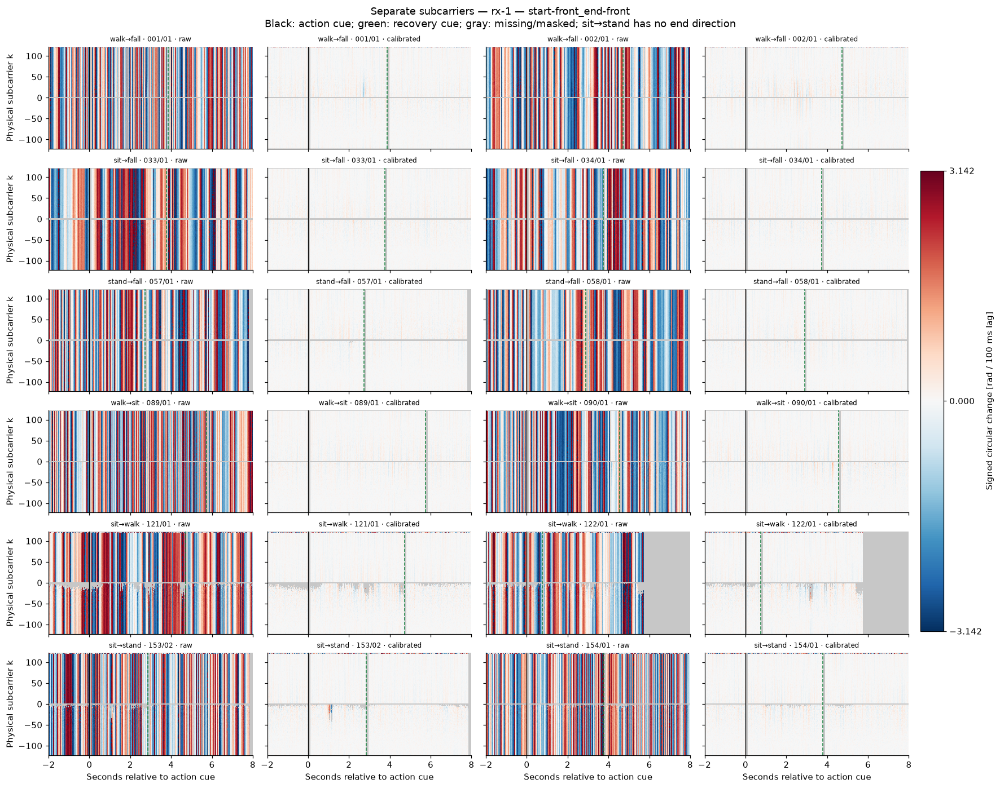

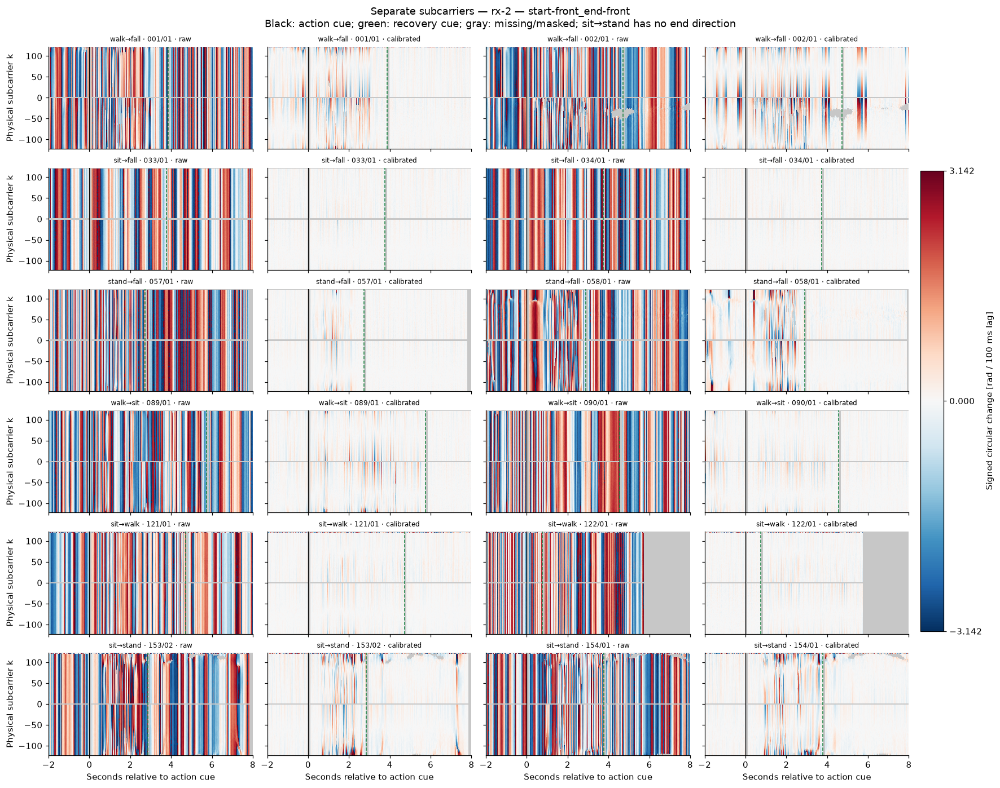

In [31]:
def draw_subcarrier_heatmap(ax, view: dict, representation: str, limit: float):
    # Split the observed time axis at long gaps. Never paint a missing interval
    # by stretching an adjacent packet's color across it.
    times = view["seconds"] - view["bounds"]["action"][0]
    visible = (times >= SUBCARRIER_VIEW_SECONDS[0]) & (times <= SUBCARRIER_VIEW_SECONDS[1])
    selected = np.flatnonzero(visible)
    period = 1.0 / view["nominal_rate_hz"]
    mesh = None
    if len(selected):
        cuts = np.flatnonzero(np.diff(times[selected]) > SUBCARRIER_MAX_PLOT_GAP_SECONDS) + 1
        segments = np.split(selected, cuts)
        tone_edges = np.r_[view["subcarriers"] - 0.5, view["subcarriers"][-1] + 0.5]
        for segment in segments:
            t = times[segment]
            # Midpoint cell edges retain irregular packet positions. At each
            # segment boundary, a half nominal period bounds the final cell.
            edges = np.r_[t[0] - period / 2, (t[:-1] + t[1:]) / 2, t[-1] + period / 2]
            mesh = ax.pcolormesh(
                edges, tone_edges,
                np.ma.masked_invalid(view[representation][segment].T),
                cmap=subcarrier_cmap, vmin=-limit, vmax=limit, shading="flat",
                rasterized=True,
            )
    ax.axvline(0, color="black", lw=0.9)
    recovery = view["bounds"]["recovery"][0] - view["bounds"]["action"][0]
    ax.axvline(recovery, color="#15803d", lw=1, ls="--")
    ax.set_xlim(*SUBCARRIER_VIEW_SECONDS)
    ax.set_ylim(view["subcarriers"][0] - 0.5, view["subcarriers"][-1] + 0.5)
    ax.set_facecolor("0.78")
    ax.grid(False)
    return mesh


subcarrier_cmap = plt.get_cmap("RdBu_r").copy()
subcarrier_cmap.set_bad("0.78")
subcarrier_figures = []
for receiver_id in RX_COLORS:
    fig, axes = plt.subplots(
        len(SUBCARRIER_LABELS), 2 * SUBCARRIER_REPETITIONS,
        figsize=(4 * 2 * SUBCARRIER_REPETITIONS, 2.1 * len(SUBCARRIER_LABELS)),
        sharex=True, sharey=True, squeeze=False, layout="constrained",
    )
    mesh = None
    for row, label in enumerate(SUBCARRIER_LABELS):
        candidates = subcarrier_selection.loc[subcarrier_selection["label"].eq(label)]
        for repetition in range(1, SUBCARRIER_REPETITIONS + 1):
            chosen = candidates.loc[candidates["display_repetition"].eq(repetition)]
            candidate = chosen.iloc[0] if not chosen.empty else None
            view = subcarrier_views.get((candidate.attempt_id, receiver_id)) if candidate is not None else None
            for offset, representation in enumerate(SCORE_COLUMNS):
                col = 2 * (repetition - 1) + offset
                ax = axes[row, col]
                if view is None:
                    ax.text(0.5, 0.5, "No matching recording", transform=ax.transAxes,
                            ha="center", va="center", fontsize=9)
                    ax.set_facecolor("0.78")
                else:
                    drawn = draw_subcarrier_heatmap(ax, view, representation, np.pi)
                    if drawn is not None:
                        mesh = drawn
                identity = candidate.attempt_id if candidate is not None else "missing"
                ax.set_title(f"{LABEL_DISPLAY[label]} · {identity} · {representation}", fontsize=8)
                if col == 0:
                    ax.set_ylabel("Physical subcarrier k")
                if row == len(SUBCARRIER_LABELS) - 1:
                    ax.set_xlabel("Seconds relative to action cue")
    if mesh is not None:
        fig.colorbar(mesh, ax=axes, shrink=0.65, pad=0.01,
                     ticks=[-np.pi, 0, np.pi], label="Signed circular change [rad / 100 ms lag]")
    fig.suptitle(f"Separate subcarriers — {receiver_id} — {subcarrier_condition_name}\n"
                 "Black: action cue; green: recovery cue; gray: missing/masked; sit→stand has no end direction")
    filename = f"{subcarrier_condition_name}_{receiver_id}_full-range.png"
    fig.savefig(SUBCARRIER_FIGURE_DIR / filename, dpi=130)
    subcarrier_figures.append(filename)
    plt.show()

### 6.2 Fixed-scale detail of calibrated changes

The next panels show the same calibrated matrices at a fixed ±0.25 radian color
limit. Values outside the limit are saturated for display; the saved matrices
retain their original values. Each title reports the fraction of finite cells
inside the displayed time window that exceeds this limit in absolute value.
The scale is shared across activities, repetitions, and receivers. It is not
normalized separately for each image or chosen to maximize a class difference.

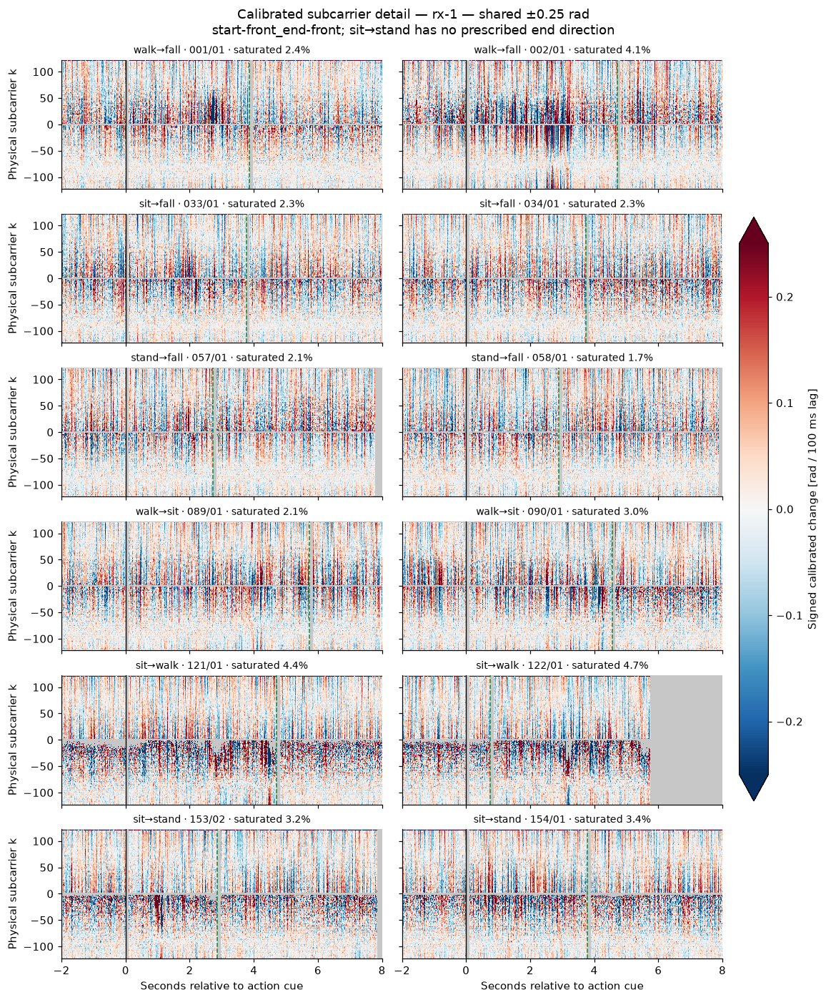

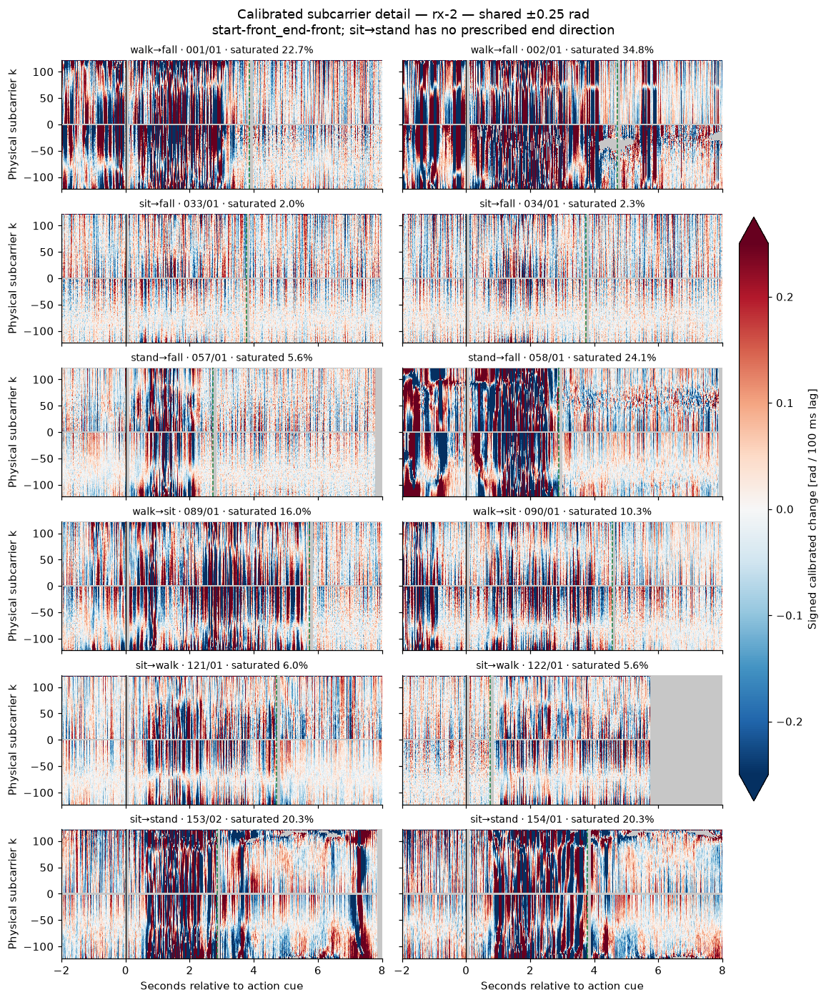

In [32]:
for receiver_id in RX_COLORS:
    fig, axes = plt.subplots(
        len(SUBCARRIER_LABELS), SUBCARRIER_REPETITIONS,
        figsize=(5.2 * SUBCARRIER_REPETITIONS, 2.1 * len(SUBCARRIER_LABELS)),
        sharex=True, sharey=True, squeeze=False, layout="constrained",
    )
    mesh = None
    for row, label in enumerate(SUBCARRIER_LABELS):
        candidates = subcarrier_selection.loc[subcarrier_selection["label"].eq(label)]
        for repetition in range(1, SUBCARRIER_REPETITIONS + 1):
            ax = axes[row, repetition - 1]
            chosen = candidates.loc[candidates["display_repetition"].eq(repetition)]
            candidate = chosen.iloc[0] if not chosen.empty else None
            view = subcarrier_views.get((candidate.attempt_id, receiver_id)) if candidate is not None else None
            if view is None:
                ax.text(0.5, 0.5, "No matching recording", transform=ax.transAxes,
                        ha="center", va="center", fontsize=9)
                ax.set_facecolor("0.78")
            else:
                drawn = draw_subcarrier_heatmap(ax, view, "calibrated", SUBCARRIER_DETAIL_LIMIT_RAD)
                if drawn is not None:
                    mesh = drawn
                relative = view["seconds"] - view["bounds"]["action"][0]
                inside = (relative >= SUBCARRIER_VIEW_SECONDS[0]) & (relative <= SUBCARRIER_VIEW_SECONDS[1])
                visible_values = view["calibrated"][inside]
                finite = visible_values[np.isfinite(visible_values)]
                saturated = np.mean(np.abs(finite) > SUBCARRIER_DETAIL_LIMIT_RAD) if len(finite) else np.nan
                ax.set_title(f"{LABEL_DISPLAY[label]} · {candidate.attempt_id} · saturated {saturated:.1%}", fontsize=9)
            if repetition == 1:
                ax.set_ylabel("Physical subcarrier k")
            if row == len(SUBCARRIER_LABELS) - 1:
                ax.set_xlabel("Seconds relative to action cue")
    if mesh is not None:
        fig.colorbar(mesh, ax=axes, shrink=0.65, pad=0.02, extend="both",
                     label="Signed calibrated change [rad / 100 ms lag]")
    fig.suptitle(f"Calibrated subcarrier detail — {receiver_id} — shared ±{SUBCARRIER_DETAIL_LIMIT_RAD} rad\n"
                 f"{subcarrier_condition_name}; sit→stand has no prescribed end direction")
    filename = f"{subcarrier_condition_name}_{receiver_id}_calibrated-detail.png"
    fig.savefig(SUBCARRIER_FIGURE_DIR / filename, dpi=130)
    subcarrier_figures.append(filename)
    plt.show()

In [33]:
subcarrier_selection.to_csv(
    SUBCARRIER_OUTPUT_DIR / f"{subcarrier_condition_name}_selection.csv", index=False
)
subcarrier_diagnostics.to_csv(
    SUBCARRIER_OUTPUT_DIR / f"{subcarrier_condition_name}_diagnostics.csv", index=False
)
subcarrier_code_paths = [ROOT / "src/fall_detection" / name for name in (
    "analysis/phase_motion.py", "analysis/phase_signals.py",
    "radio/preprocessing/phase.py", "radio/acquisition/clock_sync.py",
)]
subcarrier_notebook_code = "\n".join(
    "".join(cell["source"]) for cell in
    read_json(ROOT / "notebooks/02_simple_eda.ipynb")["cells"] if cell["cell_type"] == "code"
)
subcarrier_parameters = {
    "session_id": session_id, "participant_id": effective_participant,
    "lag_seconds": SUBCARRIER_LAG_SECONDS, "max_actual_lag_seconds": 1.5 * SUBCARRIER_LAG_SECONDS,
    "start_direction": SUBCARRIER_START_DIRECTION, "end_direction": SUBCARRIER_END_DIRECTION,
    "include_unspecified_end": SUBCARRIER_INCLUDE_UNSPECIFIED_END,
    "labels": list(SUBCARRIER_LABELS), "max_repetitions": SUBCARRIER_REPETITIONS,
    "selection": "First eligible attempt ids within the requested direction condition; no signal ranking.",
    "view_seconds": list(SUBCARRIER_VIEW_SECONDS),
    "full_color_limit_rad": float(np.pi), "detail_color_limit_rad": SUBCARRIER_DETAIL_LIMIT_RAD,
    "max_plot_gap_seconds": SUBCARRIER_MAX_PLOT_GAP_SECONDS,
    "matrix_storage_dtype": "float32", "matrix_shape": "packets x signed physical subcarriers",
    "phase_codes": dict(enumerate(PHASE_ORDER)), "unassigned_phase_code": -1,
    "representations": ["raw_change", "calibrated_change"],
    "validity": "Identical per-packet/per-tone finite mask for raw and calibrated; same-phase lag endpoints.",
    "aggregation": "None across subcarriers or packets; no temporal filter or trace resampling.",
    "source_metadata_sha256": burst_parameters["source_metadata_sha256"],
    "notebook_code_sha256": hashlib.sha256(subcarrier_notebook_code.encode()).hexdigest(),
    "code_sha256": {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                    for path in subcarrier_code_paths},
    "export_matrices": EXPORT_SUBCARRIER_MATRICES,
    "figures": subcarrier_figures,
}
(SUBCARRIER_OUTPUT_DIR / f"{subcarrier_condition_name}_parameters.json").write_text(
    json.dumps(subcarrier_parameters, indent=2) + "\n"
)
print("Matrix exports and selection diagnostics:", SUBCARRIER_OUTPUT_DIR.relative_to(ROOT))
print("Heatmaps:", SUBCARRIER_FIGURE_DIR.relative_to(ROOT))

Matrix exports and selection diagnostics: data/interim/simple-eda/20261026T174653764289Z/subcarrier-phase-changes
Heatmaps: docs/figures/simple-eda/20261026T174653764289Z/subcarriers


### Reading the separate-subcarrier comparison

Look for time-localized patches, coordinated changes over neighboring physical
tones, and signed sequences that recur across repetitions. Compare the same
activity across its two attempts before contrasting activities. A single bright
patch is insufficient: direction, receiver, countdown noise, and missing values
can change the appearance. At changes near ±π, the sign itself is ambiguous
because the circular direction can flip across that boundary.

This default condition is a small, deterministic subset of the session. Change
the direction controls and rerun section 6 to inspect other conditions; each
condition gets separate gallery and selection filenames. The NPZ matrices retain
all recorded packet times and physical slots, including values outside the plot
window and outside the detail color limit. No discriminative subcarrier has
been selected, and these panels do not establish held-out class separation.